# Hydrogen bond comparative analysis

In [147]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate

## Load data

Two analysis methods per replicate.

### WT

In [148]:
WT_dfs = []
for rep in range(1, 4):
    df_gmx = pd.read_csv(f'../../data/1YVL_noNTD/WT/rep{rep}/analysis/002_hbonds/hbonds_gmx_ext.csv')
    df_mda = pd.read_csv(f'../../data/1YVL_noNTD/WT/rep{rep}/analysis/002_hbonds/hbonds_mda_ext.csv')
    WT_dfs.append([df_gmx, df_mda])


In [149]:
WT_dfs[0][0].columns

Index(['donor', 'hydrogen', 'acceptor', 'count', 'frame%', 'donor_res_name',
       'donor_res_num', 'donor_atom_name', 'donor_chain', 'acceptor_res_name',
       'acceptor_res_num', 'acceptor_atom_name', 'acceptor_chain',
       'donor_type', 'acceptor_type', 'donor_res_num_adjusted',
       'acceptor_res_num_adjusted', 'donor_section', 'acceptor_section'],
      dtype='object')

In [150]:
WT_dfs[0][0].shape

(233, 19)

In [151]:
key_cols = ['donor', 'acceptor', 'hydrogen']
WT_dfs[0][0][WT_dfs[0][0].duplicated(subset=key_cols, keep=False)][key_cols + ['hydrogen']].head(20)

,donor,acceptor,hydrogen,hydrogen


### T385M

In [152]:
T385M_dfs = []
for rep in range(1, 4):
    df_gmx = pd.read_csv(f'../../data/1YVL_noNTD/T385M/rep{rep}/analysis/002_hbonds/hbonds_gmx_ext.csv')
    df_mda = pd.read_csv(f'../../data/1YVL_noNTD/T385M/rep{rep}/analysis/002_hbonds/hbonds_mda_ext.csv')
    T385M_dfs.append([df_gmx, df_mda])


## Method comparison (gmx vs mda)

Number and ratio of overlapping hydrogen bonds between methods, per replicate.

In [153]:
def method_overlap(df_list, frame_cutoff = 0):
    key_cols = ['donor', 'acceptor', 'hydrogen']
    for i in range(len(df_list)):

        gmx_filtered = df_list[i][0][key_cols][df_list[i][0]['frame%'] > frame_cutoff]
        mda_filtered = df_list[i][1][key_cols][df_list[i][1]['frame%'] > frame_cutoff]

        overlap1 = pd.merge(
            gmx_filtered,
            mda_filtered,
            how='inner'
        )

        total_bonds = gmx_filtered.shape[0] + mda_filtered.shape[0]
        ratio = len(overlap1) / total_bonds

        print(f"Replicate {i}")
        print(f"GMX bonds: {gmx_filtered.shape[0]}, MDA bonds: {mda_filtered.shape[0]}")
        print(f"Number of overlapping hydrogen bonds: {len(overlap1)} out of {total_bonds}. Ratio: {ratio}")

In [154]:
method_overlap(WT_dfs)

Replicate 0
GMX bonds: 233, MDA bonds: 258
Number of overlapping hydrogen bonds: 231 out of 491. Ratio: 0.47046843177189407
Replicate 1
GMX bonds: 243, MDA bonds: 278
Number of overlapping hydrogen bonds: 243 out of 521. Ratio: 0.46641074856046066
Replicate 2
GMX bonds: 240, MDA bonds: 271
Number of overlapping hydrogen bonds: 234 out of 511. Ratio: 0.45792563600782776


In [155]:
method_overlap(T385M_dfs)

Replicate 0
GMX bonds: 225, MDA bonds: 267
Number of overlapping hydrogen bonds: 222 out of 492. Ratio: 0.45121951219512196
Replicate 1
GMX bonds: 185, MDA bonds: 223
Number of overlapping hydrogen bonds: 182 out of 408. Ratio: 0.44607843137254904
Replicate 2
GMX bonds: 303, MDA bonds: 345
Number of overlapping hydrogen bonds: 296 out of 648. Ratio: 0.4567901234567901


Same overlap analysis, filtering out hydrogen bonds identified in < 10 \% of the frames.

In [156]:
method_overlap(WT_dfs, 10)

Replicate 0
GMX bonds: 45, MDA bonds: 65
Number of overlapping hydrogen bonds: 45 out of 110. Ratio: 0.4090909090909091
Replicate 1
GMX bonds: 52, MDA bonds: 72
Number of overlapping hydrogen bonds: 52 out of 124. Ratio: 0.41935483870967744
Replicate 2
GMX bonds: 37, MDA bonds: 53
Number of overlapping hydrogen bonds: 35 out of 90. Ratio: 0.3888888888888889


In [157]:
method_overlap(T385M_dfs, 10)

Replicate 0
GMX bonds: 44, MDA bonds: 63
Number of overlapping hydrogen bonds: 43 out of 107. Ratio: 0.40186915887850466
Replicate 1
GMX bonds: 20, MDA bonds: 26
Number of overlapping hydrogen bonds: 20 out of 46. Ratio: 0.43478260869565216
Replicate 2
GMX bonds: 34, MDA bonds: 50
Number of overlapping hydrogen bonds: 33 out of 84. Ratio: 0.39285714285714285


Plot overlap number.

In [158]:
WT_dfs_flat =  [x for xs in WT_dfs for x in xs]
T385M_dfs_flat =  [x for xs in T385M_dfs for x in xs]
df_all = pd.concat(WT_dfs_flat + T385M_dfs_flat)

In [159]:
len(WT_dfs_flat)

6

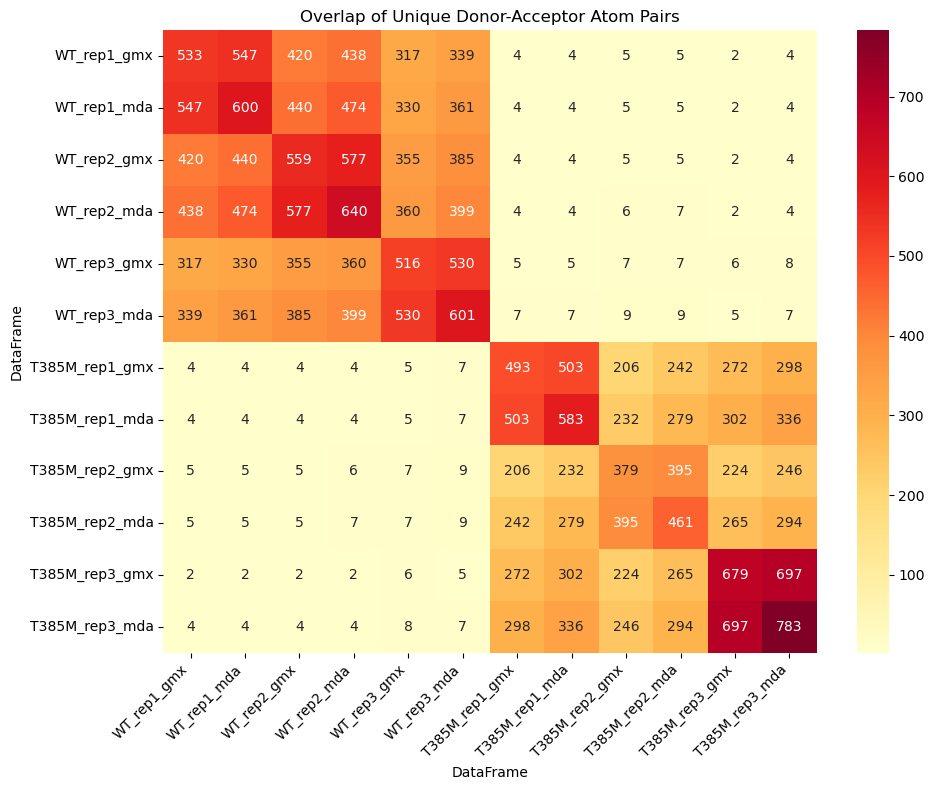

In [160]:
# Combine WT and T385M DataFrames
all_dfs_flat = WT_dfs_flat + T385M_dfs_flat

# Key columns for triplets
key_cols = ['donor', 'acceptor']

# Labels for DataFrames
labels = ['WT_rep1_gmx', 'WT_rep1_mda', 
          'WT_rep2_gmx', 'WT_rep2_mda', 'WT_rep3_gmx', 'WT_rep3_mda',
          'T385M_rep1_gmx', 'T385M_rep1_mda', 
          'T385M_rep2_gmx', 'T385M_rep2_mda', 'T385M_rep3_gmx', 'T385M_rep3_mda']

# Verify lengths match
n_labels = len(labels)
n_dfs = len(all_dfs_flat)
if n_labels != n_dfs:
    raise ValueError(f"Number of labels ({n_labels}) does not match number of DataFrames ({n_dfs})")

# Matrix to store overlap counts
overlap_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df1_triplets = all_dfs_flat[i][key_cols]
        df2_triplets = all_dfs_flat[j][key_cols]
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        # Store the count of overlapping triplets
        overlap_matrix[i, j] = len(overlap)

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_matrix, 
            annot=True, 
            fmt='.0f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap of Unique Donor-Acceptor Atom Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

Verify that there are no common donor-hydrogen-acceptor atom triplets identified between WT and T385M.

In [161]:
# Key columns
key_cols = ['donor', 'acceptor', 'hydrogen']

# Aggregate unique triplets from WT_dfs_flat
WT_triplets = pd.concat([df[key_cols] for df in WT_dfs_flat], ignore_index=True).drop_duplicates()

# Aggregate unique triplets from T385M_dfs_flat
T385M_triplets = pd.concat([df[key_cols] for df in T385M_dfs_flat], ignore_index=True).drop_duplicates()

# Find overlapping triplets
overlap = pd.merge(WT_triplets, T385M_triplets, how='inner', on=key_cols)

# Report results
if overlap.empty:
    print("No common ['donor', 'hydrogen', 'acceptor'] triplets between WT and T385M DataFrames.")
else:
    print(f"Found {len(overlap)} common triplets:")
    print(overlap)

# Optional: Show number of unique triplets in each group
print(f"Unique WT triplets: {len(WT_triplets)}")
print(f"Unique T385M triplets: {len(T385M_triplets)}")

Found 8 common triplets:
   donor  acceptor  hydrogen
0   2356     12748      2357
1  13595       537     13596
2  13595       538     13596
3   2339     12748      2341
4  13595       540     13596
5   4557      9567      4559
6  13351      2487     13352
7   4557      9566      4559
Unique WT triplets: 457
Unique T385M triplets: 553


For a less stringent comparison, consider the donor and acceptor residue numbers instead of specific atoms.

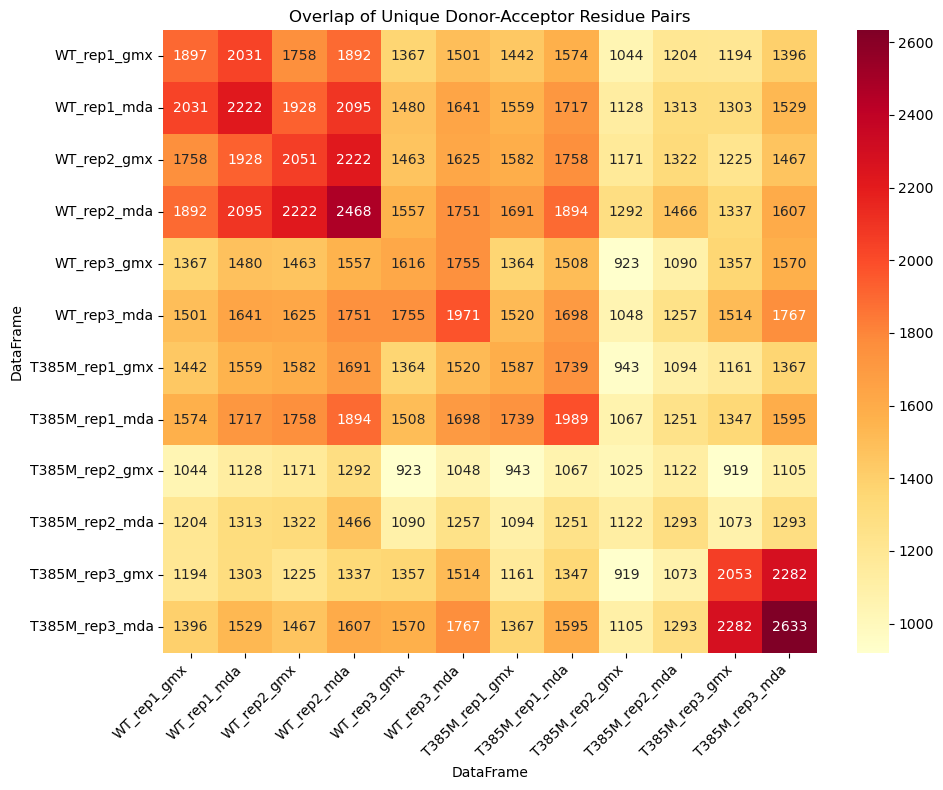

In [162]:
# Combine WT and T385M DataFrames
all_dfs_flat = WT_dfs_flat + T385M_dfs_flat

# Key columns for triplets
key_cols = ['donor_res_num', 'acceptor_res_num']

# Labels for DataFrames
labels = ['WT_rep1_gmx', 'WT_rep1_mda', 
          'WT_rep2_gmx', 'WT_rep2_mda', 'WT_rep3_gmx', 'WT_rep3_mda',
          'T385M_rep1_gmx', 'T385M_rep1_mda', 
          'T385M_rep2_gmx', 'T385M_rep2_mda', 'T385M_rep3_gmx', 'T385M_rep3_mda']

# Verify lengths match
n_labels = len(labels)
n_dfs = len(all_dfs_flat)
if n_labels != n_dfs:
    raise ValueError(f"Number of labels ({n_labels}) does not match number of DataFrames ({n_dfs})")

# Matrix to store overlap counts
overlap_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df2_triplets = all_dfs_flat[j][key_cols]
        df1_triplets = all_dfs_flat[i][key_cols]
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        # Store the count of overlapping triplets
        overlap_matrix[i, j] = len(overlap)

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_matrix, 
            annot=True, 
            fmt='.0f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap of Unique Donor-Acceptor Residue Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

Plot overlap ratios.

[45, 49, 50, 52, 63, 65, 51, 57, 55, 60, 77, 77]


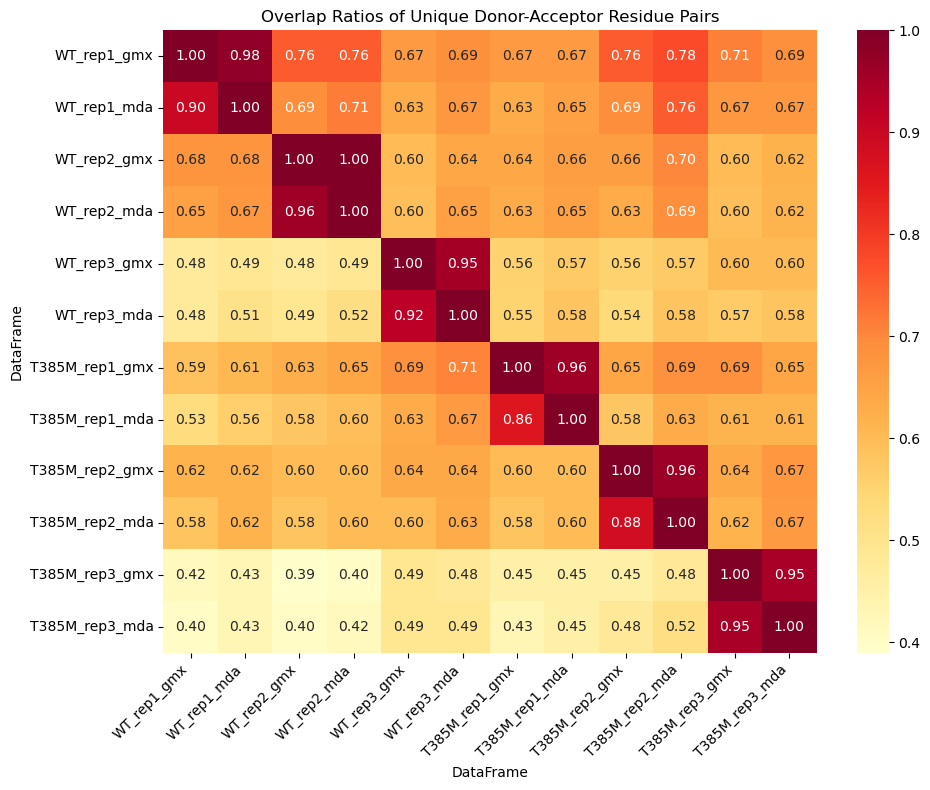

In [163]:
key_cols = ['donor_res_num', 'acceptor_res_num']
total_unique = [len(df[key_cols].drop_duplicates()) for df in all_dfs_flat]

print(total_unique)


# Matrix to store overlap counts
overlap_ratio_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df1_triplets = all_dfs_flat[i][key_cols].drop_duplicates()
        df2_triplets = all_dfs_flat[j][key_cols].drop_duplicates()
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        
        # Calculate ratio relative to total unique triplets in df[i] (y-axis)
        ratio = len(overlap) / total_unique[i] if total_unique[i] > 0 else 0
        overlap_ratio_matrix[i, j] = ratio

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_ratio_matrix, 
            annot=True, 
            fmt='.2f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap Ratios of Unique Donor-Acceptor Residue Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

[124, 134, 130, 149, 138, 149, 129, 152, 114, 133, 168, 187]


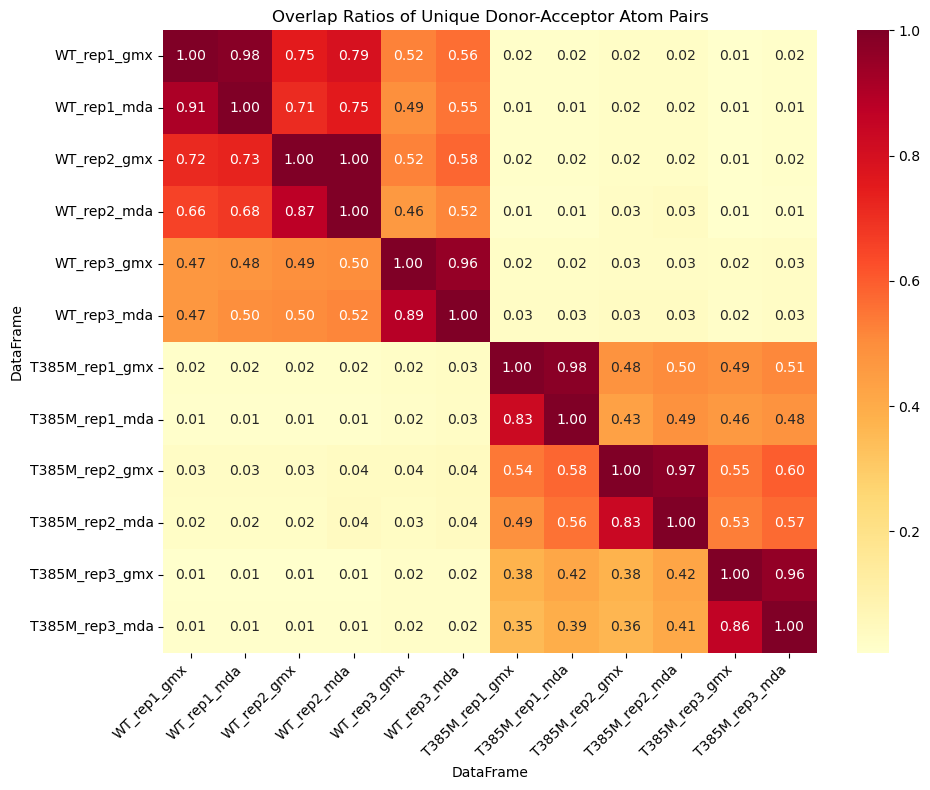

In [164]:
key_cols = ['donor', 'acceptor']
total_unique = [len(df[key_cols].drop_duplicates()) for df in all_dfs_flat]

print(total_unique)


# Matrix to store overlap counts
overlap_ratio_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df1_triplets = all_dfs_flat[i][key_cols].drop_duplicates()
        df2_triplets = all_dfs_flat[j][key_cols].drop_duplicates()
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        
        # Calculate ratio relative to total unique triplets in df[i] (y-axis)
        ratio = len(overlap) / total_unique[i] if total_unique[i] > 0 else 0
        overlap_ratio_matrix[i, j] = ratio

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_ratio_matrix, 
            annot=True, 
            fmt='.2f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap Ratios of Unique Donor-Acceptor Atom Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

## Bond distribution

In [165]:
combined_df_WT = pd.concat(WT_dfs_flat)

In [166]:
combined_df_WT.columns

Index(['donor', 'hydrogen', 'acceptor', 'count', 'frame%', 'donor_res_name',
       'donor_res_num', 'donor_atom_name', 'donor_chain', 'acceptor_res_name',
       'acceptor_res_num', 'acceptor_atom_name', 'acceptor_chain',
       'donor_type', 'acceptor_type', 'donor_res_num_adjusted',
       'acceptor_res_num_adjusted', 'donor_section', 'acceptor_section'],
      dtype='object')

In [167]:
combined_df_WT["donor_type"].value_counts()

protein    1523
Name: donor_type, dtype: int64

In [168]:
print(combined_df_WT[combined_df_WT["donor_type"] == "protein"]["frame%"].mean())

6.859457023606728


### WT

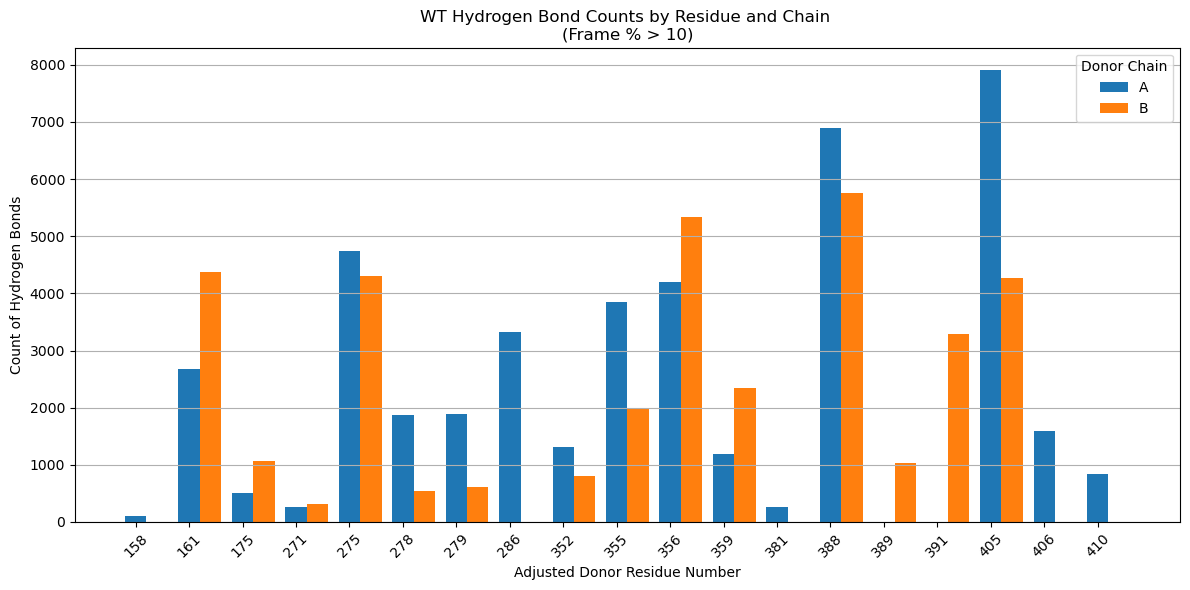

In [169]:
filtered_df = combined_df_WT[combined_df_WT['frame%'] > 10]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='donor_chain',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('WT Hydrogen Bond Counts by Residue and Chain \n(Frame % > 10)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Donor Chain')
plt.tight_layout()

# Show the plot
plt.show()

Acceptor section. Are the acceptor atoms in the DNA backbone or in the bases?

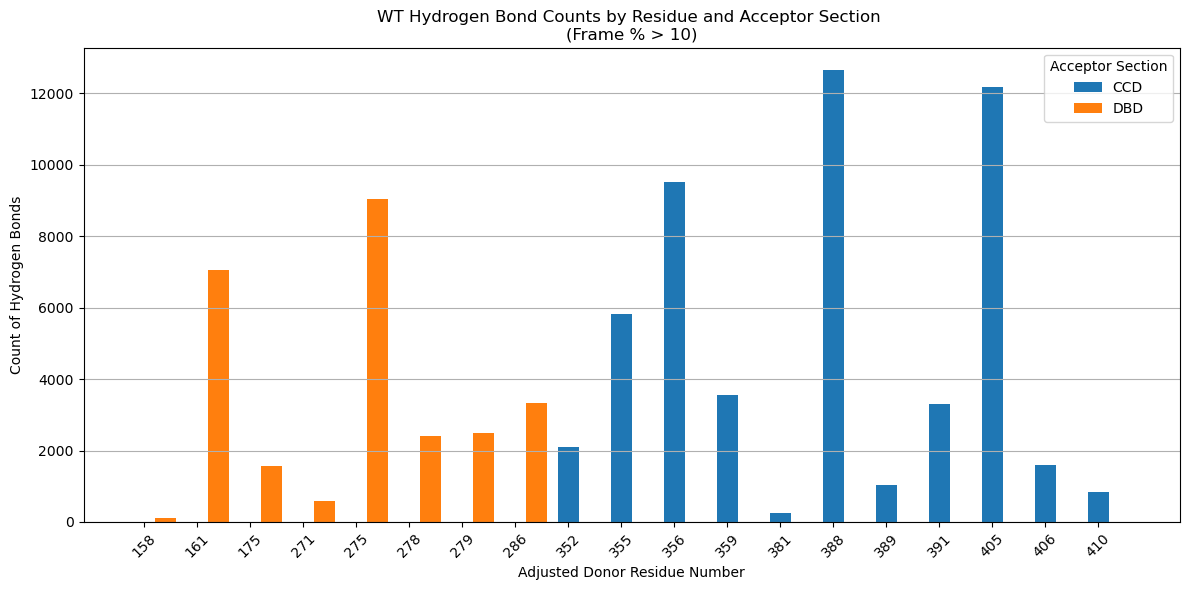

In [170]:
filtered_df = combined_df_WT[combined_df_WT['frame%'] > 10]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='acceptor_section',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('WT Hydrogen Bond Counts by Residue and Acceptor Section \n(Frame % > 10)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Acceptor Section')
plt.tight_layout()

# Show the plot
plt.show()

In [ ]:
total_frames_WT = 1000 * len(WT_dfs) * len(WT_dfs[0])

In [245]:
WT_chain_df = combined_df_WT[combined_df_WT['frame%'] > 10].copy()

WT_chain_df['chain_A'] = np.where(
    WT_chain_df['donor_chain'] == 'A',
    WT_chain_df['donor_res_num_adjusted'],
    WT_chain_df['acceptor_res_num_adjusted']
)
WT_chain_df['chain_B'] = np.where(
    WT_chain_df['donor_chain'] == 'B',
    WT_chain_df['donor_res_num_adjusted'],
    WT_chain_df['acceptor_res_num_adjusted']
)

In [251]:
WT_chain_df[(WT_chain_df['chain_A'] == 157) & (WT_chain_df['chain_B'] == 356)]['count'].sum()

5337

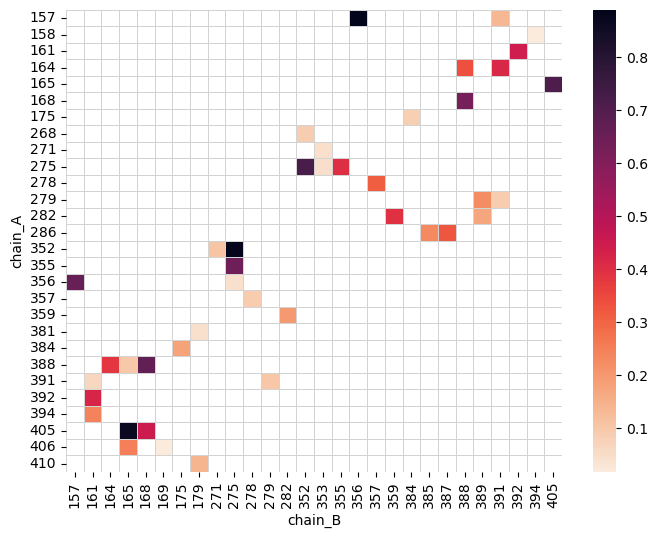

In [252]:
df_pivot = WT_chain_df.pivot_table(
    index='chain_A',
    columns='chain_B',
    values='count',
    aggfunc='sum',
) / total_frames_WT

plt.figure(figsize=(8, 6))

sns.heatmap(df_pivot, cmap='rocket_r', annot = False, linewidths=0.5, linecolor='lightgray')
plt.show()

#### Summary tables filtered - count > 10%
For 3 replicates and 2 methods, a threshold of count > 600 is equivalent to > 10%.

In [171]:
occ_th = 100 * len(WT_dfs) * len(WT_dfs[0])
occ_th

600

In [172]:
total_frames_WT = 1000 * len(WT_dfs) * len(WT_dfs[0])
total_frames_WT

6000

**Chain A**

In [173]:
group_columns = combined_df_WT.columns.difference(["frame%", "count", "hydrogen"])
WT_count = combined_df_WT.groupby(list(group_columns))['count'].sum().reset_index()

WT_count.sort_values("count", ascending=False).head()

,acceptor,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num,acceptor_res_num_adjusted,acceptor_section,acceptor_type,donor,donor_atom_name,donor_chain,donor_res_name,donor_res_num,donor_res_num_adjusted,donor_section,donor_type,count
211,12733,O,B,GLN,219,352,DBD,protein,2356,NE2,A,GLN,142,275,CCD,protein,4044
196,11393,OE1,B,GLN,142,275,CCD,protein,3739,ND2,A,ASN,222,355,DBD,protein,3867
71,3695,O,A,GLN,219,352,DBD,protein,11394,NE2,B,GLN,142,275,CCD,protein,3461
153,9624,OD2,B,ASP,35,168,CCD,protein,4307,NZ,A,LYS,255,388,DBD,protein,3024
129,9445,OE1,B,GLU,24,157,CCD,protein,3757,OH,A,TYR,223,356,DBD,protein,2869


In [174]:
WT_count[(WT_count['donor_chain'] == 'A') & (WT_count["count"] > occ_th)].shape

(28, 17)

In [175]:
summary_cols = WT_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
WT_count[(WT_count['donor_chain'] == 'A') & (WT_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
211,O,B,GLN,352,DBD,4044,NE2,GLN,275,CCD
196,OE1,B,GLN,275,CCD,3867,ND2,ASN,355,DBD
153,OD2,B,ASP,168,CCD,3024,NZ,LYS,388,DBD
129,OE1,B,GLU,157,CCD,2869,OH,TYR,356,DBD
239,O,B,MET,392,DBD,2776,NZ,LYS,161,CCD
144,OD2,B,ASP,165,CCD,2744,NH2,ARG,405,DBD
234,O,B,THR,387,DBD,2232,NZ,LYS,286,CCD
226,OD1,B,ASN,357,DBD,2222,NZ,LYS,278,CCD
143,OD2,B,ASP,165,CCD,2079,NH1,ARG,405,DBD
132,OE2,B,GLU,164,CCD,1784,NZ,LYS,388,DBD


In [176]:
WT_monoA_summary = WT_count[(WT_count['donor_chain'] == 'A') & (WT_count["count"] > occ_th)][summary_cols]
WT_monoA_summary['occupancy'] = round(WT_monoA_summary['count'] / total_frames_WT, 2)
WT_monoA_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
211,O,B,GLN,352,DBD,4044,NE2,GLN,275,CCD,0.67
196,OE1,B,GLN,275,CCD,3867,ND2,ASN,355,DBD,0.64
153,OD2,B,ASP,168,CCD,3024,NZ,LYS,388,DBD,0.50
129,OE1,B,GLU,157,CCD,2869,OH,TYR,356,DBD,0.48
239,O,B,MET,392,DBD,2776,NZ,LYS,161,CCD,0.46


**Monomer B**

In [177]:
WT_count[(WT_count['donor_chain'] == 'B') & (WT_count["count"] > occ_th)].shape

(26, 17)

In [178]:
summary_cols = WT_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
WT_count[(WT_count['donor_chain'] == 'B') & (WT_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
71,O,A,GLN,352,DBD,3461,NE2,GLN,275,CCD
2,OE2,A,GLU,157,CCD,2813,OH,TYR,356,DBD
104,O,A,MET,392,DBD,2542,NZ,LYS,161,CCD
0,OE1,A,GLU,157,CCD,2524,OH,TYR,356,DBD
22,OD2,A,ASP,168,CCD,2498,NZ,LYS,388,DBD
53,OE1,A,GLN,275,CCD,2112,ND2,ASN,355,DBD
3,OE1,A,GLU,164,CCD,1994,NZ,LYS,388,DBD
95,O,A,GLY,384,DBD,1835,NZ,LYS,175,CCD
60,OE2,A,GLU,282,CCD,1599,NZ,LYS,359,DBD
19,OD1,A,ASP,168,CCD,1546,NZ,LYS,388,DBD


In [179]:
WT_monoB_summary = WT_count[(WT_count['donor_chain'] == 'B') & (WT_count["count"] > occ_th)][summary_cols]
WT_monoB_summary['occupancy'] = round(WT_monoB_summary['count'] / total_frames_WT, 2)
WT_monoB_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
71,O,A,GLN,352,DBD,3461,NE2,GLN,275,CCD,0.58
2,OE2,A,GLU,157,CCD,2813,OH,TYR,356,DBD,0.47
22,OD2,A,ASP,168,CCD,2498,NZ,LYS,388,DBD,0.42
104,O,A,MET,392,DBD,2542,NZ,LYS,161,CCD,0.42
0,OE1,A,GLU,157,CCD,2524,OH,TYR,356,DBD,0.42


In [180]:
WT_summary = pd.concat([WT_monoA_summary, WT_monoB_summary],keys= ['Monomer A', 'Monomer B'])

In [181]:
WT_summary

acceptor_atom_name acceptor_chain acceptor_res_name  \
Monomer A 129                OE1              B               GLU   
          130                OE2              B               GLU   
          131                OE1              B               GLU   
          132                OE2              B               GLU   
          136                OD1              B               ASP   
          139                OD1              B               ASP   
          140                OD1              B               ASP   
          143                OD2              B               ASP   
          144                OD2              B               ASP   
          145                OD2              B               ASP   
          148                OD1              B               ASP   
          149                OD1              B               ASP   
          151                OD1              B               ASP   
          153                OD2              B               ASP   
          165                OD1              B               ASN   
          195                OE1              B               GLN   
          196                OE1              B               GLN   
          202                OE1              B               GLU   
          203                OE2              B               GLU   
          211                  O              B               GLN   
          226                OD1              B               ASN   
          230                  O              B               GLY   
          231                OG1              B               THR   
          234                  O              B               THR   
          235                  O              B               VAL   
          237                OD1              B               ASN   
          239                  O              B               MET   
          244                OE1              B               GLU   
Monomer B 0                  OE1              A               GLU   
          1                  OE1              A               GLU   
          2                  OE2              A               GLU   
          3                  OE1              A               GLU   
          4                  OE1              A               GLU   
          6                  OE2              A               GLU   
          7                  OE2              A               GLU   
          9                  OD1              A               ASP   
          11                 OD1              A               ASP   
          13                 OD2              A               ASP   
          14                 OD2              A               ASP   
          19                 OD1              A               ASP   
          22                 OD2              A               ASP   
          53                 OE1              A               GLN   
          58                 OE1              A               GLU   
          60                 OE2              A               GLU   
          61                 OE2              A               GLU   
          66                 OE1              A               GLN   
          71                   O              A               GLN   
          87                 OD1              A               ASN   
          95                   O              A               GLY   
          100                OD1              A               ASN   
          101                OD1              A               ASN   
          104                  O              A               MET   
          111                OE1              A               GLU   
          114                OE2              A               GLU   

               acceptor_res_num_adjusted acceptor_section  count  \
Monomer A 129                        157              CCD   2869   
          130                        157              CCD   1095   
          131 

In [182]:
WT_summary.to_csv('results/1YVL_WT_summary.csv')

### T385M

Find unique pairs of donor-acceptor atoms and sum their counts across replicates and methods. The hydrogen atom number is not taken into account to consider it as the "same bond".

In [183]:
combined_df_T385M = pd.concat(T385M_dfs_flat)

In [184]:
group_columns = combined_df_T385M.columns.difference(["frame%", "count", "hydrogen"])
T385M_count = combined_df_T385M.groupby(list(group_columns))['count'].sum().reset_index()

T385M_count.sort_values("count", ascending=False).head()

,acceptor,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num,acceptor_res_num_adjusted,acceptor_section,acceptor_type,donor,donor_atom_name,donor_chain,donor_res_name,donor_res_num,donor_res_num_adjusted,donor_section,donor_type,count
290,13398,OD1,B,ASN,258,391,DBD,protein,2435,NZ,A,LYS,146,279,CCD,protein,3043
19,585,OD1,A,ASP,35,168,CCD,protein,13351,NZ,B,LYS,255,388,DBD,protein,2827
4,525,OE1,A,GLU,31,164,CCD,protein,13351,NZ,B,LYS,255,388,DBD,protein,2786
234,11396,OE1,B,GLN,142,275,CCD,protein,3739,ND2,A,ASN,222,355,DBD,protein,2210
80,2487,OE2,A,GLU,149,282,CCD,protein,13351,NZ,B,LYS,255,388,DBD,protein,1991


In [185]:
T385M_count.shape

(310, 17)

Comparison between monomers A and B.

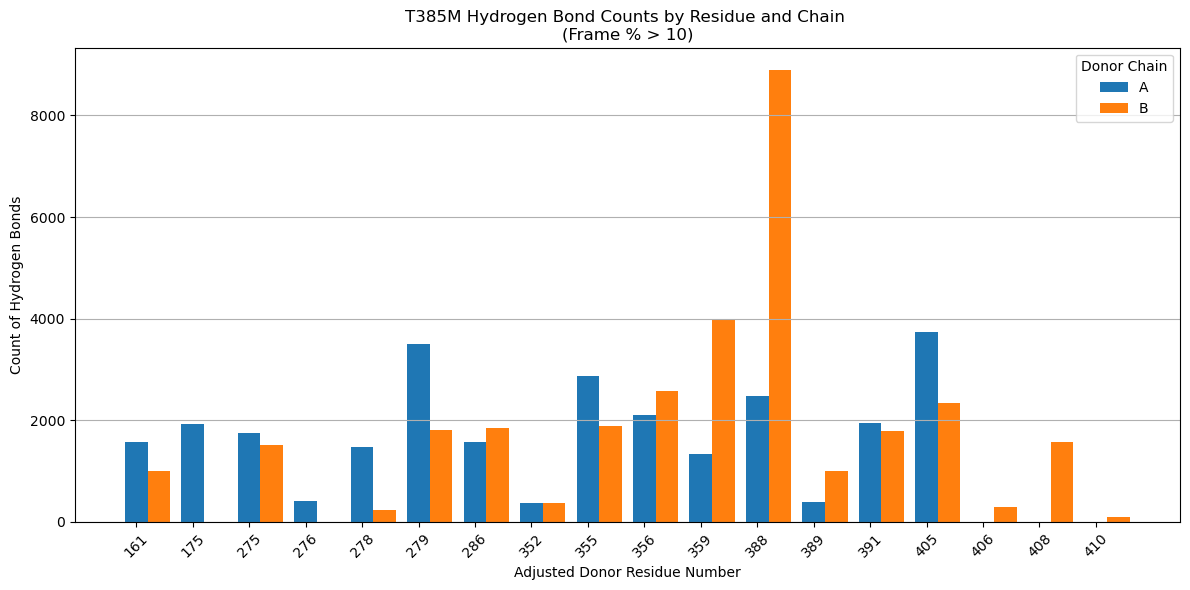

In [186]:
filtered_df = combined_df_T385M[combined_df_T385M['frame%'] > 10]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='donor_chain',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('T385M Hydrogen Bond Counts by Residue and Chain \n(Frame % > 10)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Donor Chain')
plt.tight_layout()

# Show the plot
plt.show()

Acceptor section. Are the acceptor atoms in the DNA backbone or in the bases?

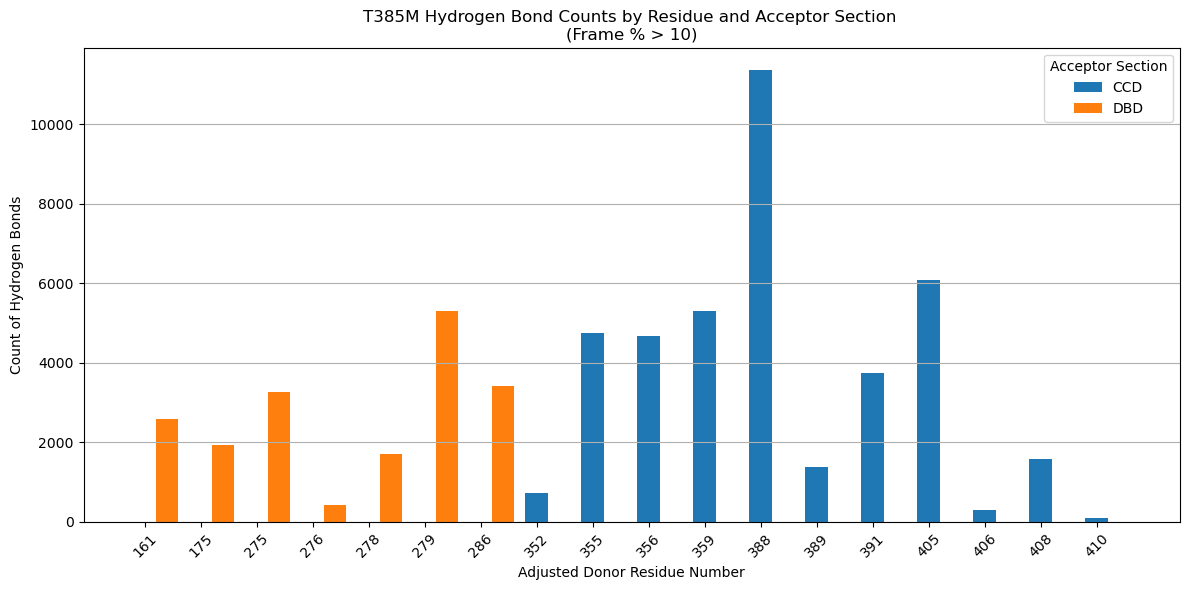

In [187]:
filtered_df = combined_df_T385M[combined_df_T385M['frame%'] > 10]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='acceptor_section',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('T385M Hydrogen Bond Counts by Residue and Acceptor Section \n(Frame % > 10)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Acceptor Section')
plt.tight_layout()

# Show the plot
plt.show()

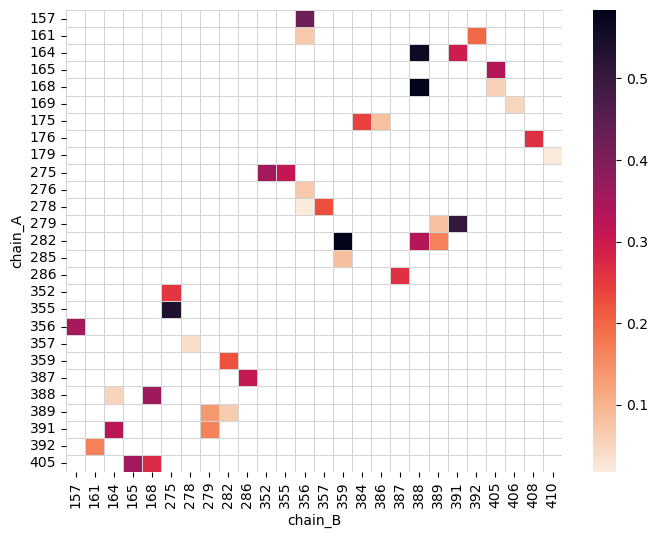

In [254]:
T385M_chain_df = combined_df_T385M[combined_df_T385M['frame%'] > 10].copy()

T385M_chain_df['chain_A'] = np.where(
    T385M_chain_df['donor_chain'] == 'A',
    T385M_chain_df['donor_res_num_adjusted'],
    T385M_chain_df['acceptor_res_num_adjusted']
)
T385M_chain_df['chain_B'] = np.where(
    T385M_chain_df['donor_chain'] == 'B',
    T385M_chain_df['donor_res_num_adjusted'],
    T385M_chain_df['acceptor_res_num_adjusted']
)
T385M_chain_df[(T385M_chain_df['chain_A'] == 157) & (T385M_chain_df['chain_B'] == 356)]['count'].sum()
df_pivot = T385M_chain_df.pivot_table(
    index='chain_A',
    columns='chain_B',
    values='count',
    aggfunc='sum',
) / total_frames_WT

plt.figure(figsize=(8, 6))

sns.heatmap(df_pivot, cmap='rocket_r', annot = False, linewidths=0.5, linecolor='lightgray')
plt.show()

#### Summary tables filtered - count > 10%
For 4 replicates and 2 methods, a threshold of count > 800 is equivalent to > 10%.

In [188]:
occ_th = 100 * len(WT_dfs) * len(WT_dfs[0])
occ_th

600

In [189]:
total_frames_T385M = 1000 * len(T385M_dfs) * len(T385M_dfs[0])
total_frames_T385M

6000

**Monomer A**

In [190]:
T385M_count[(T385M_count['donor_chain'] == 'A') & (T385M_count["count"] > occ_th)].shape

(24, 17)

In [191]:
summary_cols = T385M_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
T385M_count[(T385M_count['donor_chain'] == 'A') & (T385M_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
290,OD1,B,ASN,391,DBD,3043,NZ,LYS,279,CCD
234,OE1,B,GLN,275,CCD,2210,ND2,ASN,355,DBD
278,OD1,B,ASN,357,DBD,1982,NZ,LYS,278,CCD
284,O,B,GLY,384,DBD,1801,NZ,LYS,175,CCD
287,O,B,THR,387,DBD,1798,NZ,LYS,286,CCD
179,OD2,B,ASP,168,CCD,1761,NZ,LYS,388,DBD
257,O,B,GLN,352,DBD,1538,NE2,GLN,275,CCD
157,OE2,B,GLU,157,CCD,1495,OH,TYR,356,DBD
249,OE2,B,GLU,282,CCD,1305,NZ,LYS,359,DBD
292,O,B,MET,392,DBD,1198,NZ,LYS,161,CCD


In [192]:
T385M_monoA_summary = T385M_count[(T385M_count['donor_chain'] == 'A') & (T385M_count["count"] > occ_th)][summary_cols]
T385M_monoA_summary['occupancy'] = round(T385M_monoA_summary['count'] / total_frames_T385M, 2)
T385M_monoA_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
290,OD1,B,ASN,391,DBD,3043,NZ,LYS,279,CCD,0.51
234,OE1,B,GLN,275,CCD,2210,ND2,ASN,355,DBD,0.37
278,OD1,B,ASN,357,DBD,1982,NZ,LYS,278,CCD,0.33
287,O,B,THR,387,DBD,1798,NZ,LYS,286,CCD,0.30
284,O,B,GLY,384,DBD,1801,NZ,LYS,175,CCD,0.30


**Monomer B**

In [193]:
T385M_count[(T385M_count['donor_chain'] == 'B') & (T385M_count["count"] > occ_th)].shape

(24, 17)

In [194]:
summary_cols = T385M_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
T385M_count[(T385M_count['donor_chain'] == 'B') & (T385M_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
19,OD1,A,ASP,168,CCD,2827,NZ,LYS,388,DBD
4,OE1,A,GLU,164,CCD,2786,NZ,LYS,388,DBD
80,OE2,A,GLU,282,CCD,1991,NZ,LYS,388,DBD
67,OE1,A,GLN,275,CCD,1932,ND2,ASN,355,DBD
79,OE2,A,GLU,282,CCD,1854,NZ,LYS,359,DBD
122,O,A,THR,387,DBD,1843,NZ,LYS,286,CCD
77,OE1,A,GLU,282,CCD,1721,NZ,LYS,359,DBD
0,OE1,A,GLU,157,CCD,1691,OH,TYR,356,DBD
28,OG1,A,THR,176,CCD,1587,NE2,GLN,408,DBD
21,OD2,A,ASP,168,CCD,1545,NZ,LYS,388,DBD


In [195]:
T385M_monoB_summary = T385M_count[(T385M_count['donor_chain'] == 'B') & (T385M_count["count"] > occ_th)][summary_cols]
T385M_monoB_summary['occupancy'] = round(T385M_monoB_summary['count'] / total_frames_T385M, 2)
T385M_monoB_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
19,OD1,A,ASP,168,CCD,2827,NZ,LYS,388,DBD,0.47
4,OE1,A,GLU,164,CCD,2786,NZ,LYS,388,DBD,0.46
80,OE2,A,GLU,282,CCD,1991,NZ,LYS,388,DBD,0.33
67,OE1,A,GLN,275,CCD,1932,ND2,ASN,355,DBD,0.32
79,OE2,A,GLU,282,CCD,1854,NZ,LYS,359,DBD,0.31


In [196]:
T385M_summary = pd.concat([T385M_monoA_summary, T385M_monoB_summary],keys= ['Monomer A', 'Monomer B'])

In [197]:
T385M_summary

acceptor_atom_name acceptor_chain acceptor_res_name  \
Monomer A 156                OE1              B               GLU   
          157                OE2              B               GLU   
          159                OE1              B               GLU   
          162                OE2              B               GLU   
          163                OE2              B               GLU   
          169                OD1              B               ASP   
          171                OD2              B               ASP   
          172                OD2              B               ASP   
          174                OD1              B               ASP   
          179                OD2              B               ASP   
          182                OD2              B               ASP   
          234                OE1              B               GLN   
          238                NE2              B               GLN   
          246                OE1              B               GLU   
          249                OE2              B               GLU   
          257                  O              B               GLN   
          276                  O              B               TYR   
          278                OD1              B               ASN   
          284                  O              B               GLY   
          285                ND1              B               HIE   
          287                  O              B               THR   
          288                  O              B               VAL   
          290                OD1              B               ASN   
          292                  O              B               MET   
Monomer B 0                  OE1              A               GLU   
          2                  OE2              A               GLU   
          4                  OE1              A               GLU   
          5                  OE1              A               GLU   
          6                  OE2              A               GLU   
          7                  OE2              A               GLU   
          15                 OD2              A               ASP   
          16                 OD2              A               ASP   
          19                 OD1              A               ASP   
          21                 OD2              A               ASP   
          28                 OG1              A               THR   
          33                 OD1              A               ASN   
          67                 OE1              A               GLN   
          77                 OE1              A               GLU   
          78                 OE1              A               GLU   
          79                 OE2              A               GLU   
          80                 OE2              A               GLU   
          81                 OE1              A               GLN   
          91                   O              A               GLN   
          108                OD1              A               ASN   
          122                  O              A               THR   
          123                  O              A               VAL   
          125                OD1              A               ASN   
          127                  O              A               MET   

               acceptor_res_num_adjusted acceptor_section  count  \
Monomer A 156                        157              CCD    611   
          157                        157              CCD   1495   
          159                        164              CCD    973   
          162                        164              CCD    686   
          163                        164              CCD    972   
          169                        165              CCD    619   
          171                        165              CCD    958   
          172                        165              CCD    890   
          174       

In [198]:
T385M_summary.sort_values("donor_res_num_adjusted").to_csv('results/1YVL_T385M_summary.csv')

#### Summary tables unfiltered

In [199]:
group_columns = combined_df_T385M.columns.difference(["frame%", "count", "hydrogen"])
T385M_count_count = combined_df_T385M.groupby(list(group_columns))['count'].sum().reset_index()
summary_cols = T385M_count.columns.difference(["acceptor", "donor", "hydrogen", "donor_res_num", "acceptor_res_num"])


In [200]:
T385M_monoA_summary_unfiltered = T385M_count[(T385M_count['donor_chain'] == 'A') | (T385M_count['acceptor_chain'] == 'A')][summary_cols]
T385M_monoA_summary_unfiltered['occupancy'] = round(T385M_monoA_summary_unfiltered['count'] / total_frames_T385M, 2)

In [201]:
T385M_monoB_summary_unfiltered = T385M_count[(T385M_count['donor_chain'] == 'B') | (T385M_count['acceptor_chain'] == 'B')][summary_cols]
T385M_monoB_summary_unfiltered['occupancy'] = round(T385M_monoB_summary_unfiltered['count'] / total_frames_WT, 2)

In [202]:
T385M_summary_unfiltered = pd.concat([T385M_monoA_summary_unfiltered, T385M_monoB_summary_unfiltered],keys= ['Monomer A', 'Monomer B'])
T385M_summary_unfiltered.to_csv('results/1YVL_T385M_summary_unfiltered.csv')

Prepare for Latex formatting.

In [203]:
# Function to extract protein residue info
def extract_protein_info(row):
    if row['donor_type'] == 'protein':
        return pd.Series({
            'res_num': row['donor_res_num_adjusted'],
            'res_name': row['donor_res_name'],
            'atom': row['donor_atom_name'],
        })
    else:
        return pd.Series({
            'res_num': row['acceptor_res_num_adjusted'],
            'res_name': row['acceptor_res_name'],
            'atom': row['acceptor_atom_name'],
        })

# Function to extract monomer info
def extract_monomer_info(row):
    if row['donor_type'] == 'protein':
        return pd.Series({
            'chain': row['acceptor_chain'],
            'res_num': row['acceptor_res_num_adjusted'],
            'res_name': row['acceptor_res_name'],
            'section': row['acceptor_section'],
            'atom': row['acceptor_atom_name'],
            'occupancy': row['occupancy']
        })
    else:
        return pd.Series({
            'chain': row['donor_chain'],
            'res_num': row['donor_res_num_adjusted'],
            'res_name': row['donor_res_name'],
            'section': row['donor_section'],
            'atom': row['donor_atom_name'],
            'occupancy': row['occupancy']
        })

In [204]:
# Load the CSV file
df = pd.read_csv('results/1YVL_T385M_summary_unfiltered.csv', skipinitialspace=True)
# Filter by occupancy >= 0.05
df = df[df['occupancy'] >= 0.05]

# Identify whether Monomer A or B is involved
df['monomer'] = df.iloc[:, 0]


# Add the extracted columns
df[['res_num', 'res_name', 'atom']] = df.apply(extract_protein_info, axis=1)
df[['mono_chain', 'mono_res_num', 'mono_res_name', 'mono_section', 'mono_atom', 'mono_occupancy']] = df.apply(extract_monomer_info, axis=1)

# Group data by protein residue
grouped = df.groupby(['res_num', 'res_name', 'atom'])

# Store rows for the final dataframe
final_rows = []

for group_keys, group_df in grouped:
    monomer_a_rows = group_df[group_df['monomer'] == 'Monomer A'][['mono_chain', 'mono_res_num', 'mono_res_name', 'mono_section', 'mono_atom', 'mono_occupancy']].values.tolist()
    monomer_b_rows = group_df[group_df['monomer'] == 'Monomer B'][['mono_chain', 'mono_res_num', 'mono_res_name', 'mono_section', 'mono_atom', 'mono_occupancy']].values.tolist()
    
    # Pad shorter list with empty entries
    max_len = max(len(monomer_a_rows), len(monomer_b_rows))
    monomer_a_rows += [['']*6] * (max_len - len(monomer_a_rows))
    monomer_b_rows += [['']*6] * (max_len - len(monomer_b_rows))
    
    for a, b in zip(monomer_a_rows, monomer_b_rows):
        final_rows.append(list(group_keys) + a + b)

# Create final DataFrame
columns = ['res_num', 'res_name', 'atom',
           'A_chain', 'A_res_num', 'A_res_name', 'A_section', 'A_atom', 'A_occupancy',
           'B_chain', 'B_res_num', 'B_res_name', 'B_section', 'B_atom', 'B_occupancy']

final_df = pd.DataFrame(final_rows, columns=columns)

# Save to CSV
final_df.to_csv('results/1YVL_T385M_protein_monomer_comparison.csv', index=False)

In [205]:

df = pd.read_csv('results/1YVL_T385M_protein_monomer_comparison.csv')

# Ensure residue numbers are integers
df['res_num'] = df['res_num'].astype(int)
df['A_res_num'] = df['A_res_num'].apply(lambda x: int(x) if pd.notna(x) else x)
df['B_res_num'] = df['B_res_num'].apply(lambda x: int(x) if pd.notna(x) else x)

# Format occupancy columns to 2 decimal places, preserve NaN
df['A_occupancy'] = df['A_occupancy'].apply(lambda x: f"{x:.2f}" if pd.notna(x) else x)
df['B_occupancy'] = df['B_occupancy'].apply(lambda x: f"{x:.2f}" if pd.notna(x) else x)


# Generate LaTeX table
latex_table = tabulate(df, headers='keys', tablefmt='latex_longtable', showindex=False)

# Save to file
with open("results/1YVL_T385M_latex.tex", "w") as f:
    f.write(latex_table)

## Comparison T385M vs WT

### Bond distribution

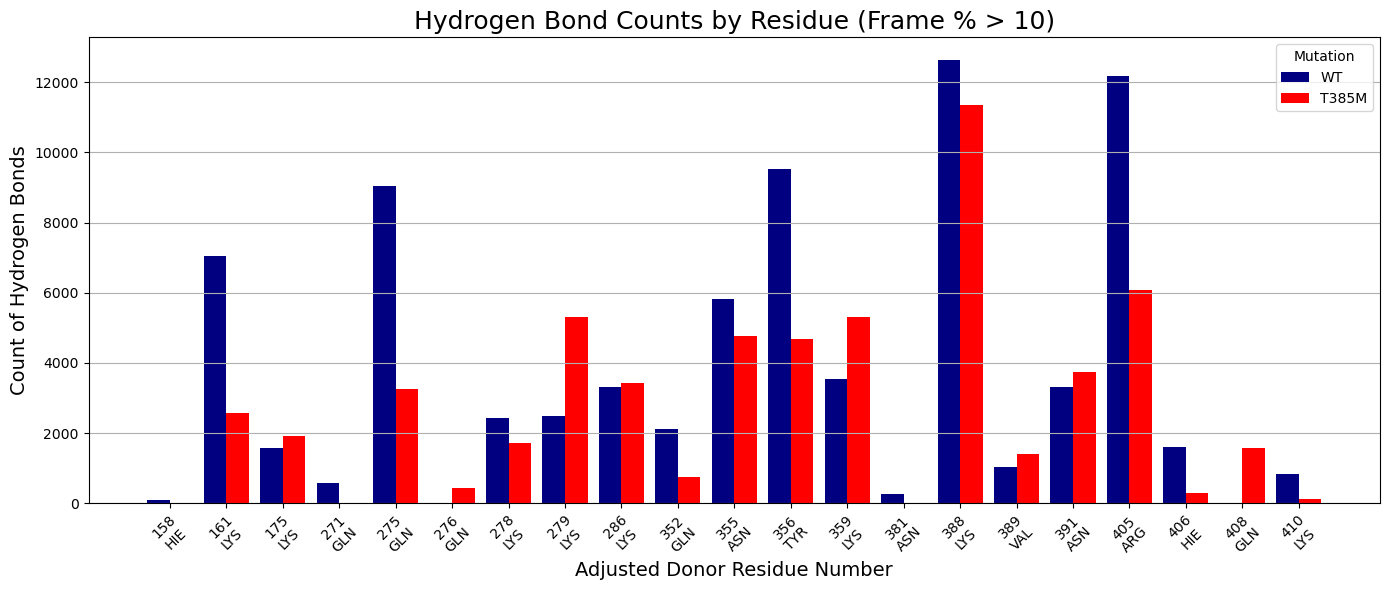

In [206]:
# Filter data for frame% > 10
filtered_df_T385M = combined_df_T385M[combined_df_T385M['frame%'] > 10]
filtered_df_WT = combined_df_WT[combined_df_WT['frame%'] > 10]

# Pivot the data to aggregate counts by donor_res_num_adjusted (no donor_chain)
pivot_df_T385M = pd.pivot_table(filtered_df_T385M, 
                                index='donor_res_num_adjusted',
                                values='count',
                                aggfunc='sum',  # Sum counts for duplicates
                                fill_value=0)   # Replace NaN with 0

pivot_df_WT = pd.pivot_table(filtered_df_WT, 
                             index='donor_res_num_adjusted',
                             values='count',
                             aggfunc='sum',  # Sum counts for duplicates
                             fill_value=0)   # Replace NaN with 0

# Align indices by taking the union of residue numbers
all_residues = sorted(set(pivot_df_T385M.index).union(set(pivot_df_WT.index)))
pivot_df_T385M = pivot_df_T385M.reindex(all_residues, fill_value=0)
pivot_df_WT = pivot_df_WT.reindex(all_residues, fill_value=0)

combined_df = pd.concat([filtered_df_WT, filtered_df_T385M], ignore_index=True)

res_name_map = (combined_df
    .drop_duplicates(subset='donor_res_num_adjusted')
    .set_index('donor_res_num_adjusted')['donor_res_name']
    .reindex(all_residues))

# x-axis labels
x_labels = [f"{num}\n{res_name_map.get(num, '')}"
    for num in all_residues
]

# Create the plot
plt.figure(figsize=(14, 6))

# Set bar width and positions
bar_width = 0.4  # Two bars (T385M and WT)
x = np.arange(len(all_residues))  # Positions for each donor residue

# Plot bars for T385M and WT
plt.bar(x - bar_width/2, 
        pivot_df_WT['count'], 
        color='navy',
        width=bar_width, 
        label='WT')
plt.bar(x + bar_width/2, 
        pivot_df_T385M['count'], 
        width=bar_width, 
        color='red',
        label='T385M')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number', fontsize=14)
plt.ylabel('Count of Hydrogen Bonds', fontsize=14)
plt.title('Hydrogen Bond Counts by Residue (Frame % > 10)', fontsize=18)
plt.xticks(x, x_labels, rotation=45)
plt.grid(axis='y')
plt.legend(title='Mutation')
plt.tight_layout()


plt.show()

Per chain

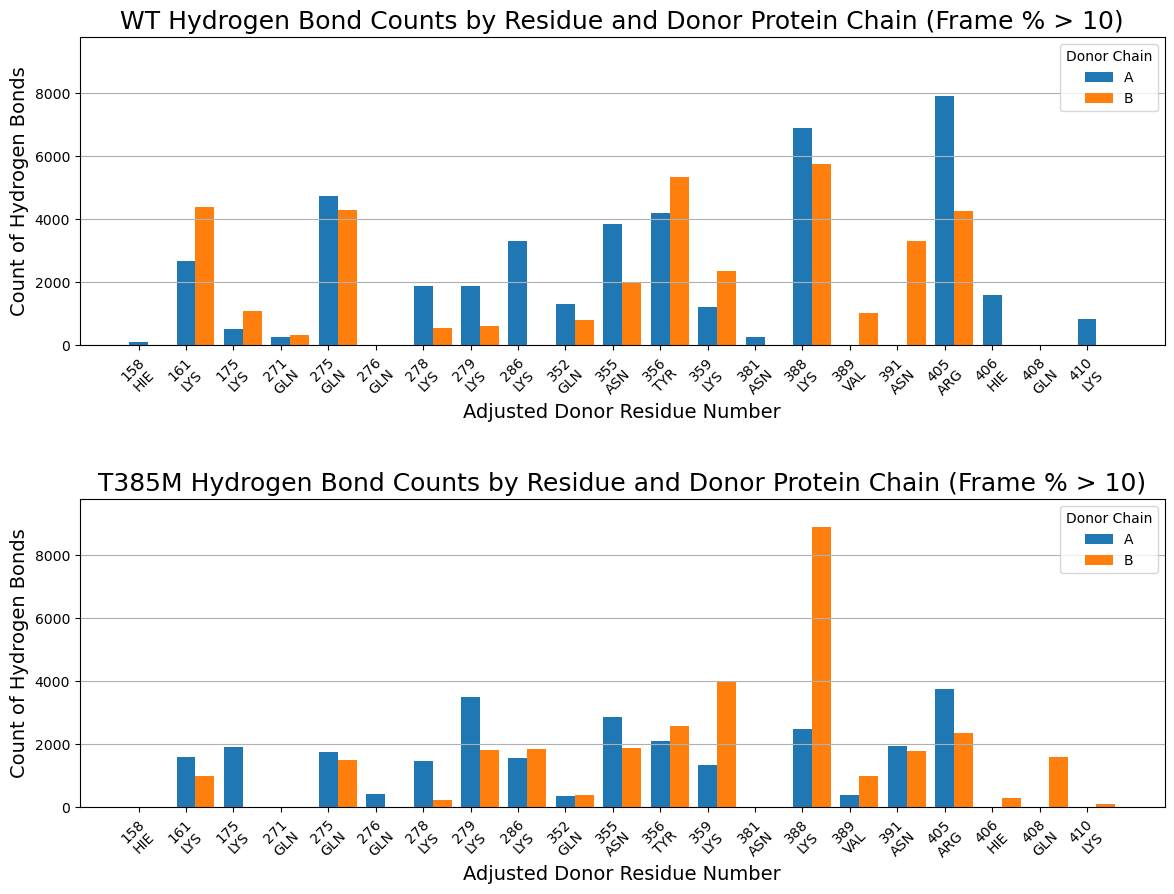

In [134]:
# Filter data for frame% > 10
filtered_df_WT = combined_df_WT[(combined_df_WT['frame%'] > 10) & ((combined_df_WT['donor_chain'] == 'A') | (combined_df_WT['donor_chain'] == 'B'))]
filtered_df_T385M = combined_df_T385M[(combined_df_T385M['frame%'] > 10) & ((combined_df_T385M['donor_chain'] == 'A') | (combined_df_T385M['donor_chain'] == 'B'))]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df_WT = pd.pivot_table(filtered_df_WT, 
                             index='donor_res_num_adjusted',
                             columns='donor_chain',
                             values='count',
                             aggfunc='sum',
                             fill_value=0)

pivot_df_T385M = pd.pivot_table(filtered_df_T385M, 
                                index='donor_res_num_adjusted',
                                columns='donor_chain',
                                values='count',
                                aggfunc='sum',
                                fill_value=0)

# Align indices by taking the union of residue numbers
all_residues = sorted(set(pivot_df_WT.index).union(set(pivot_df_T385M.index)))
pivot_df_WT = pivot_df_WT.reindex(all_residues, fill_value=0)
pivot_df_T385M = pivot_df_T385M.reindex(all_residues, fill_value=0)

# Create residue name mapping
combined_df = pd.concat([filtered_df_WT, filtered_df_T385M], ignore_index=True)
res_name_map = (combined_df
                .drop_duplicates(subset='donor_res_num_adjusted')
                .set_index('donor_res_num_adjusted')['donor_res_name']
                .reindex(all_residues)
                .fillna('Unknown'))


# Calculate joint y-axis limits
y_max = max(pivot_df_WT.values.max(), pivot_df_T385M.values.max())
y_min = min(pivot_df_WT.values.min(), pivot_df_T385M.values.min())
y_limits = [y_min, y_max * 1.1]  # Add 10% padding to max

# subplots (2 rows, 1 column)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

# Data for looping
datasets = [
    {'pivot_df': pivot_df_WT, 'ax': ax1, 'title': 'WT Hydrogen Bond Counts by Residue and Donor Protein Chain (Frame % > 10)'},
    {'pivot_df': pivot_df_T385M, 'ax': ax2, 'title': 'T385M Hydrogen Bond Counts by Residue and Donor Protein Chain (Frame % > 10)'}
]

# Plot
x = np.arange(len(all_residues))
for dataset in datasets:
    pivot_df = dataset['pivot_df']
    ax = dataset['ax']
    sections = pivot_df.columns
    n_sections = len(sections)
    bar_width = 0.8 / n_sections

    for i, section in enumerate(sections):
        ax.bar(x + i * bar_width, 
               pivot_df[section], 
               width=bar_width, 
               label=section,
               align='edge')
    
    ax.set_ylabel('Count of Hydrogen Bonds', fontsize=14)
    ax.set_xlabel('Adjusted Donor Residue Number', fontsize=14)
    ax.set_title(dataset['title'], fontsize=18)
    ax.set_xticks(x + bar_width * (n_sections - 1) / 2)
    x_labels = [f"{num}\n{res_name_map.get(num, '')}"
    for num in all_residues
    ]
    ax.set_xticklabels(x_labels, rotation=45)
    ax.set_ylim(y_limits)
    ax.grid(axis='y')
    ax.legend(title='Donor Chain')

plt.subplots_adjust(hspace=0.5)
plt.show()

In [ ]:
sns.heatmap()

### Protein as donor

**Frame %**

Text(0.5, 1.0, 'WT 385 Hydrogen Bond Frame % Distribution')

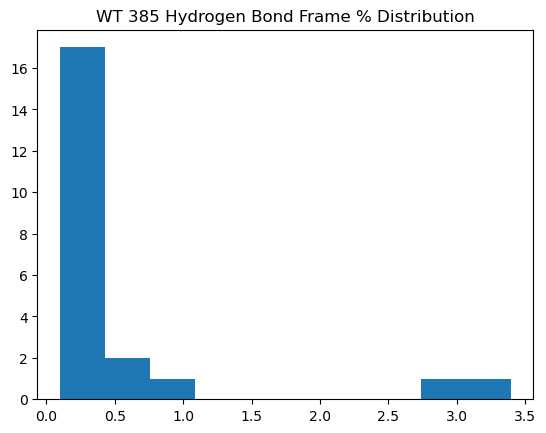

In [136]:
filtered_df = combined_df_WT[combined_df_WT['donor_res_num_adjusted'] == 385]
plt.hist(filtered_df['frame%'])
plt.title('WT 385 Hydrogen Bond Frame % Distribution')

Text(0.5, 1.0, 'T385M 385 Hydrogen Bond Frame % Distribution')

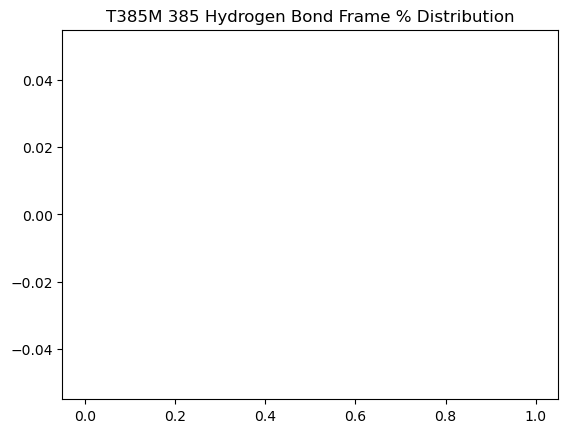

In [137]:
filtered_df = combined_df_T385M[combined_df_T385M['donor_res_num_adjusted'] == 385]
plt.hist(filtered_df['frame%'])
plt.title('T385M 385 Hydrogen Bond Frame % Distribution')

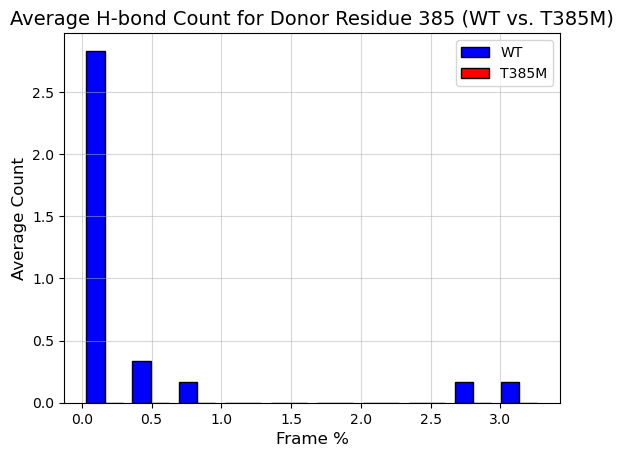

In [141]:
# Filter data
filtered_df_T385M = combined_df_T385M[combined_df_T385M['donor_res_num_adjusted'] == 385]
filtered_df_WT = combined_df_WT[combined_df_WT['donor_res_num_adjusted'] == 385]

# Common bins
bins = np.histogram(np.hstack((filtered_df_WT['frame%'], filtered_df_T385M['frame%'])))[1]
WT_counts, WT_bins = np.histogram(filtered_df_WT['frame%'], bins=bins)
mut_counts, mut_bins = np.histogram(filtered_df_T385M['frame%'], bins=bins)

# Average counts by the number of replicates
avg_WT_counts = WT_counts / (len(WT_dfs) * 2)  # 2 methods (gmx and mda)
avg_mut_counts = mut_counts / (len(T385M_dfs) * 2)  # 2 methods (gmx and mda)

# Bar positions
bar_width = (bins[1] - bins[0]) * 0.4
WT_positions = bins[:-1]
mut_positions = bins[:-1] + bar_width

# Plot
plt.bar(WT_positions, avg_WT_counts, width=bar_width, color='blue', label='WT', edgecolor='black')
plt.bar(mut_positions, avg_mut_counts, width=bar_width, color='red', label='T385M', edgecolor='black')

# Customize
plt.xlabel('Frame %', fontsize=12)
plt.ylabel('Average Count', fontsize=12)  # Updated y-axis label
plt.title('Average H-bond Count for Donor Residue 385 (WT vs. T385M)', fontsize=14)  # Updated title
# plt.xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
plt.legend(fontsize=10)
plt.grid(True, alpha=0.5)

plt.show()

In [142]:
filtered_df_T385M.shape

(0, 19)

Neighbouring residues

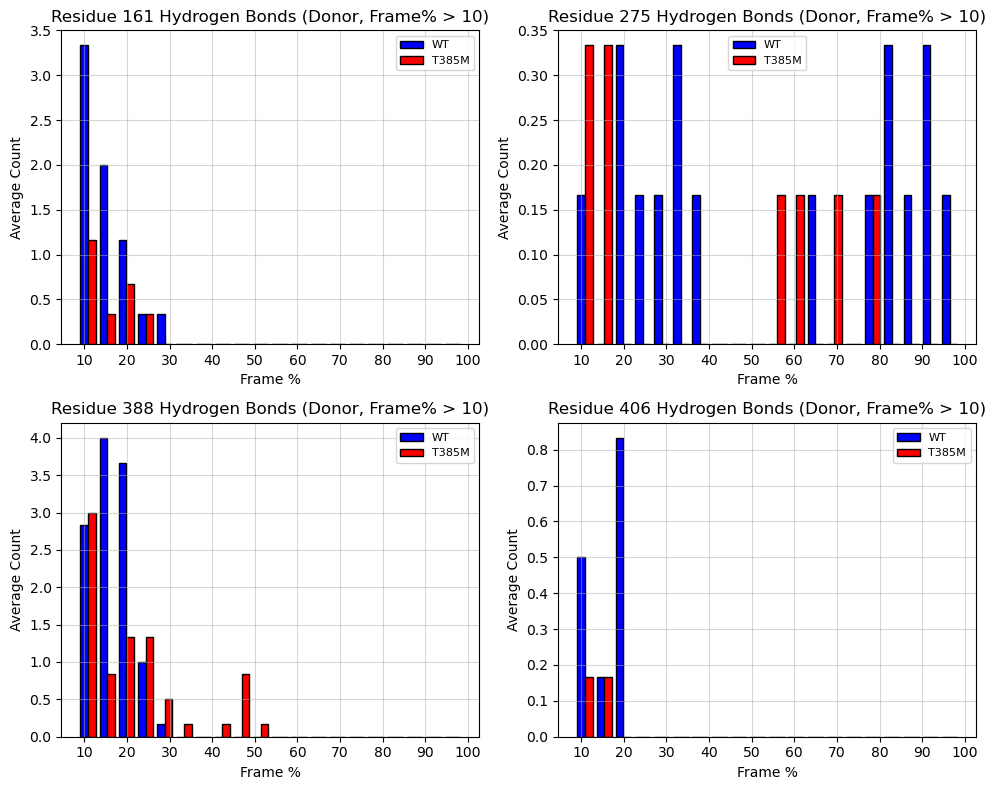

In [145]:

# Residues to plot
residues = [161, 275, 388, 406]

# Initialize a variable to track the maximum y-value
max_y_value = 0

# First pass: Calculate the maximum y-value across all residues
for residue in residues:
    # Filter data for the current residue and frame% > 10
    filtered_df_T385M = combined_df_T385M[(combined_df_T385M['donor_res_num_adjusted'] == residue) & (combined_df_T385M['frame%'] > 10)]
    filtered_df_WT = combined_df_WT[(combined_df_WT['donor_res_num_adjusted'] == residue) & (combined_df_WT['frame%'] > 10)]

    WT_counts, _ = np.histogram(filtered_df_WT['frame%'], bins=bins)
    mut_counts, _ = np.histogram(filtered_df_T385M['frame%'], bins=bins)

    # Average counts by the number of replicates x number of methods
    avg_WT_counts = WT_counts / (len(WT_dfs) * 2) 
    avg_mut_counts = mut_counts / (len(T385M_dfs) * 2) 

    # Update the maximum y-value
    max_y_value = max(max_y_value, max(avg_WT_counts), max(avg_mut_counts))

# Second pass: Plot the data
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()  # Flatten the 2D array of axes for easier indexing

for i, residue in enumerate(residues):
    # Filter data for the current residue and frame% > 10
    filtered_df_T385M = combined_df_T385M[(combined_df_T385M['donor_res_num_adjusted'] == residue) & (combined_df_T385M['frame%'] > 10)]
    filtered_df_WT = combined_df_WT[(combined_df_WT['donor_res_num_adjusted'] == residue) & (combined_df_WT['frame%'] > 10)]

    # Common bins
    bins = np.linspace(10, 100, 21)  # 21 edges for 20 bins
    WT_counts, _ = np.histogram(filtered_df_WT['frame%'], bins=bins)
    mut_counts, _ = np.histogram(filtered_df_T385M['frame%'], bins=bins)

    # Average counts by the number of replicates x number of methods
    avg_WT_counts = WT_counts / (len(WT_dfs) * 2) 
    avg_mut_counts = mut_counts / (len(T385M_dfs) * 2) 

    # Bar positions
    bar_width = (bins[1] - bins[0]) * 0.4
    WT_positions = bins[:-1]
    mut_positions = bins[:-1] + bar_width

    # Plot on the current subplot
    axes[i].bar(WT_positions, avg_WT_counts, width=bar_width, color='blue', label='WT', edgecolor='black')
    axes[i].bar(mut_positions, avg_mut_counts, width=bar_width, color='red', label='T385M', edgecolor='black')

    # Customize the subplot
    axes[i].set_xlabel('Frame %', fontsize=10)
    axes[i].set_ylabel('Average Count', fontsize=10)
    axes[i].set_title(f'Residue {residue} Hydrogen Bonds (Donor, Frame% > 10)', fontsize=12)
    axes[i].set_xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
    # axes[i].set_ylim(0, max_y_value * 1.1)  # Use the same y-axis range for all plots
    axes[i].grid(True, alpha=0.5)
    axes[i].legend(fontsize=8)

# Remove any unused subplot (if fewer than 6 residues)
for j in range(len(residues), len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.show()

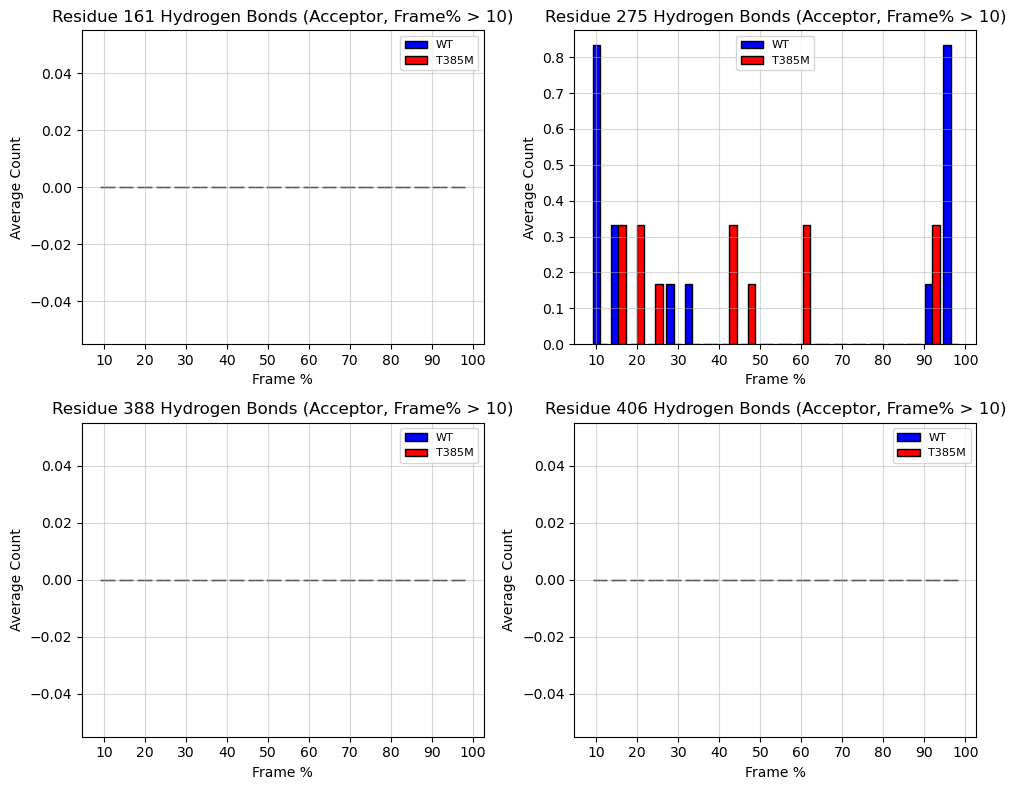

In [146]:

# Residues to plot
residues = [161, 275, 388, 406]

# Initialize a variable to track the maximum y-value
max_y_value = 0

# First pass: Calculate the maximum y-value across all residues
for residue in residues:
    # Filter data for the current residue and frame% > 10
    filtered_df_T385M = combined_df_T385M[(combined_df_T385M['acceptor_res_num_adjusted'] == residue) & (combined_df_T385M['frame%'] > 10)]
    filtered_df_WT = combined_df_WT[(combined_df_WT['acceptor_res_num_adjusted'] == residue) & (combined_df_WT['frame%'] > 10)]

    WT_counts, _ = np.histogram(filtered_df_WT['frame%'], bins=bins)
    mut_counts, _ = np.histogram(filtered_df_T385M['frame%'], bins=bins)

    # Average counts by the number of replicates x number of methods
    avg_WT_counts = WT_counts / (len(WT_dfs) * 2) 
    avg_mut_counts = mut_counts / (len(T385M_dfs) * 2) 

    # Update the maximum y-value
    max_y_value = max(max_y_value, max(avg_WT_counts), max(avg_mut_counts))

# Second pass: Plot the data
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()  # Flatten the 2D array of axes for easier indexing

for i, residue in enumerate(residues):
    # Filter data for the current residue and frame% > 10
    filtered_df_T385M = combined_df_T385M[(combined_df_T385M['acceptor_res_num_adjusted'] == residue) & (combined_df_T385M['frame%'] > 10)]
    filtered_df_WT = combined_df_WT[(combined_df_WT['acceptor_res_num_adjusted'] == residue) & (combined_df_WT['frame%'] > 10)]

    # Common bins
    bins = np.linspace(10, 100, 21)  # 21 edges for 20 bins
    WT_counts, _ = np.histogram(filtered_df_WT['frame%'], bins=bins)
    mut_counts, _ = np.histogram(filtered_df_T385M['frame%'], bins=bins)

    # Average counts by the number of replicates x number of methods
    avg_WT_counts = WT_counts / (len(WT_dfs) * 2) 
    avg_mut_counts = mut_counts / (len(T385M_dfs) * 2) 

    # Bar positions
    bar_width = (bins[1] - bins[0]) * 0.4
    WT_positions = bins[:-1]
    mut_positions = bins[:-1] + bar_width

    # Plot on the current subplot
    axes[i].bar(WT_positions, avg_WT_counts, width=bar_width, color='blue', label='WT', edgecolor='black')
    axes[i].bar(mut_positions, avg_mut_counts, width=bar_width, color='red', label='T385M', edgecolor='black')

    # Customize the subplot
    axes[i].set_xlabel('Frame %', fontsize=10)
    axes[i].set_ylabel('Average Count', fontsize=10)
    axes[i].set_title(f'Residue {residue} Hydrogen Bonds (Acceptor, Frame% > 10)', fontsize=12)
    axes[i].set_xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
    # axes[i].set_ylim(0, max_y_value * 1.1)  # Use the same y-axis range for all plots
    axes[i].grid(True, alpha=0.5)
    axes[i].legend(fontsize=8)

# Remove any unused subplot (if fewer than 6 residues)
for j in range(len(residues), len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.show()

Bonds where residue 385 is the donor and frame % > 10.

In [ ]:
combined_df_T385M[(combined_df_T385M['donor_res_num_adjusted'] == 385) & (combined_df_T385M['frame%'] > 10)].shape

In [ ]:
combined_df_T385M[(combined_df_T385M['donor_res_num_adjusted'] == 466) & (combined_df_T385M['frame%'] > 10)].sort_values('frame%', ascending=False).head(10)

Acceptor residue sections. Are the hydrogen bonds happening with the DNA backbone or the bases?

In [ ]:
def process_residue_data(residue, df, replicates):
    filtered_df = df[(df['donor_res_num_adjusted'] == residue) & (df['frame%'] > 10)]
    base = filtered_df[filtered_df['acceptor_section'] == 'base']
    backbone = filtered_df[filtered_df['acceptor_section'] == 'backbone']
    fixed_bins = np.linspace(10, 100, 21)  # 21 edges for 20 bins
    base_counts, _ = np.histogram(base['frame%'], bins=fixed_bins)
    backbone_counts, _ = np.histogram(backbone['frame%'], bins=fixed_bins)
    norm_base = base_counts / (replicates * 2) 
    norm_backbone = backbone_counts / (replicates * 2) 
    return norm_base, norm_backbone, fixed_bins

In [ ]:
residues = [161, 275, 388, 406]
max_y_value = 0
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharey=True)
axes = axes.flatten()

for i, residue in enumerate(residues):
    norm_base, norm_backbone, bins = process_residue_data(residue, combined_df_T385M, len(T385M_dfs))
    max_y_value = max(max_y_value, max(norm_base), max(norm_backbone))

    bar_width = (bins[1] - bins[0]) * 0.4
    axes[i].bar(bins[:-1], norm_base, width=bar_width, color='red', label='Base acceptor', edgecolor='black')
    axes[i].bar(bins[:-1] + bar_width, norm_backbone, width=bar_width, color='blue', label='Backbone acceptor', edgecolor='black')

    axes[i].set_xlabel('Frame %', fontsize=10)
    axes[i].set_ylabel('Average Count', fontsize=10)
    axes[i].set_title(f'T385M Residue {residue} Hydrogen Bonds (Donor, Frame% > 10)', fontsize=12)
    axes[i].set_xticks(np.arange(10, 101, 10))
    axes[i].tick_params(axis='y', labelleft=True)
    axes[i].set_ylim(0, max_y_value * 1.1)
    axes[i].grid(True, alpha=0.5)
    axes[i].legend(fontsize=8)

for j in range(len(residues), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**DNA residues binding to residue 466**

Note that these bonds are NOT filtered fo frame % > 10. There are no hbonds at reidue 466 in the WT, so only mutant T385M is analyzed.

In [ ]:
donor_T385M = combined_df_T385M[combined_df_T385M['donor_res_num_adjusted'] == 466]
acceptor_T385M = combined_df_T385M[combined_df_T385M['acceptor_res_num_adjusted'] == 466]

donor_counts = donor_T385M['acceptor_res_num_adjusted'].value_counts().sort_index()
acceptor_counts = acceptor_T385M['donor_res_num_adjusted'].value_counts().sort_index()

plt.figure(figsize=(10, 6))

# Get all unique residue numbers
all_res_nums = sorted(set(donor_counts.index).union(acceptor_counts.index))

# Align the counts, filling with 0 where no data exists
donor_values = [donor_counts.get(num, 0) / (len(T385M_dfs) * 2)  for num in all_res_nums]
acceptor_values = [acceptor_counts.get(num, 0) / (len(T385M_dfs) * 2) for num in all_res_nums]

# Create stacked bar plot
plt.bar(all_res_nums, donor_values, color='red', label='Acceptor DNA')
plt.bar(all_res_nums, acceptor_values, bottom=donor_values, color='blue', label='Donor DNA')

# Set x-ticks for every unit
min_residue = min(all_res_nums)
max_residue = max(all_res_nums)
plt.xticks(range(int(min_residue), int(max_residue) + 1, 1))

plt.xlabel('DNA Residue Number')
plt.ylabel('Average Count')
plt.title('DNA Donor and Acceptor Residues (Stacked), T385M residue 466')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [ ]:
# Define the DNA strands
strand1 = "CGACAGTTTCCCGGAAATGCAGC"  # Chain C, 23 nucleotides
strand2 = "GCTGCATTTCCGGGAAACTGTCG"  # Chain D, 23 nucleotides

# Create a mapping of residue numbers to nucleotide pairs
residue_to_nucleotides = {i+1: (strand1[i], strand2[i]) for i in range(23)}

# Consensus residues
consensus_residues = [8, 9, 10, 11, 13, 14, 15, 16]

In [ ]:
def plot_interactions(ax, df_donor, df_acceptor, section, title, replicates):
    # Filter for section
    donor = df_donor[df_donor['acceptor_section'] == section]
    acceptor = df_acceptor[df_acceptor['donor_section'] == section]
    
    # Count occurrences
    donor_counts = donor['acceptor_res_num_adjusted'].value_counts().sort_index()
    acceptor_counts = acceptor['donor_res_num_adjusted'].value_counts().sort_index()
    
    # Define all residue numbers (1 to 23, based on DNA strands)
    all_res_nums = list(range(1, 24))  # Residues 1 to 23 inclusive
    
    # Normalize counts, using 0 for residues with no counts
    donor_values = [donor_counts.get(num, 0) / (replicates * 2) for num in all_res_nums]
    acceptor_values = [acceptor_counts.get(num, 0) / (replicates * 2) for num in all_res_nums]
    
    # Create stacked bar plot
    ax.bar(all_res_nums, donor_values, color='red', label='Acceptor DNA')
    ax.bar(all_res_nums, acceptor_values, bottom=donor_values, color='blue', label='Donor DNA')
    
    # Set x-ticks to include all residues (1 to 23)
    ax.set_xticks(all_res_nums)
    ax.tick_params(axis='x', rotation=45)
    
    # Customize plot
    ax.set_xlabel('DNA Residue Number')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()

In [ ]:
def plot_interactions_totalcount(ax, df_donor, df_acceptor, section, title, replicates):
    # Filter for section
    donor = df_donor[df_donor['acceptor_section'] == section]
    acceptor = df_acceptor[df_acceptor['donor_section'] == section]
    
    # Count occurrences
    donor_counts = donor.groupby('acceptor_res_num_adjusted')['count'].sum()
    acceptor_counts = acceptor.groupby('donor_res_num_adjusted')['count'].sum()

    # Define all residue numbers (1 to 23, based on DNA strands)
    all_res_nums = list(range(1, 24))  # Residues 1 to 23 inclusive
    
    # Normalize counts, using 0 for residues with no counts
    avg_factor = replicates * 2  * 1000 # replicates x methods x frames
    donor_values = [donor_counts.get(num, 0) / avg_factor for num in all_res_nums]
    acceptor_values = [acceptor_counts.get(num, 0) / avg_factor for num in all_res_nums]
    
    # Create stacked bar plot
    ax.bar(all_res_nums, donor_values, color='red', label='Acceptor DNA')
    ax.bar(all_res_nums, acceptor_values, bottom=donor_values, color='blue', label='Donor DNA')
    
    # Set x-ticks to include all residues (1 to 23)
    ax.set_xticks(all_res_nums)
    ax.tick_params(axis='x', rotation=45)
    
    # Customize plot
    ax.set_xlabel('DNA Residue Number', fontsize=14)
    ax.set_ylabel('Average Count', fontsize=14)
    ax.set_title(title, fontsize=18)
    ax.grid(True, alpha=0.3)
    ax.legend()

In [ ]:
def plot_interactions_totalcount_dnachains(ax, df_donor, df_acceptor, section, chain, title_base, replicates):
    # Filter for section
    donor = df_donor[df_donor['acceptor_section'] == section]
    acceptor = df_acceptor[df_acceptor['donor_section'] == section]

    donor_chain = donor[donor['acceptor_chain'] == chain]
    acceptor_chain = acceptor[acceptor['donor_chain'] == chain]

    # Group by residue number and sum the 'count' column
    donor_counts = donor_chain.groupby('acceptor_res_num_adjusted')['count'].sum()
    acceptor_counts = acceptor_chain.groupby('donor_res_num_adjusted')['count'].sum()

    # Residue numbers and strand orientation based on chain
    if chain == 'D':
        ax.invert_xaxis()
        strand = strand2
    else:
        strand = strand1

    # Normalize counts
    avg_factor = replicates * 2 * 1000
    all_res_nums = range(1, len(strand) + 1)  # Residues 1 to 23 inclusive
    donor_values = [donor_counts.get(num, 0) / avg_factor for num in all_res_nums]
    acceptor_values = [acceptor_counts.get(num, 0) / avg_factor for num in all_res_nums]

    # Plot stacked bar chart
    ax.bar(all_res_nums, donor_values, color='red', label='Acceptor DNA')
    ax.bar(all_res_nums, acceptor_values, bottom=donor_values, color='blue', label='Donor DNA')

    # Titles and labels
    ax.set_ylabel('Average Counts', fontsize=14)
    ax.tick_params(axis='y', labelsize=12)
    ax.set_title(f"{title_base} - Chain {chain}", fontsize=18)
    ax.grid(True, alpha=0.3)
    ax.legend()

    # Create mapping of residue numbers to nucleotides for selected strand and orientation
    # Set x-ticks and labels
    residue_to_nucleotides = {res: strand[i] for i, res in enumerate(all_res_nums)}
    labels = [f"{res}\n{residue_to_nucleotides.get(res, 'N/A')}" for res in all_res_nums]

    ax.set_xticks(all_res_nums)
    ax.set_xticklabels(labels, fontsize=12, rotation=0, ha='right', va='top')

    # Color consensus sequence residues green
    for i, label in enumerate(ax.get_xticklabels()):
        if all_res_nums[i] in consensus_residues:
            label.set_color('green')
            label.set_weight('bold')

    ax.set_xlabel(f"Residue Number\nChain {chain}", fontsize=14)

In [ ]:
def plot_dnaseq_bb_base_totalcount(df_donor, df_acceptor, replicates, section1, title1, section2, title2):
    # Create figure with two subplots
    fig, axes = plt.subplots(2, 2, figsize=(20, 10), sharey=True)

    # Plot backbone and base interactions (assuming plot_interactions is defined)
    plot_interactions_totalcount_dnachains(axes[0,0], df_donor, df_acceptor, section1, 'C', title1, replicates)
    plot_interactions_totalcount_dnachains(axes[0,1], df_donor, df_acceptor, section2, 'C', title2, replicates)
    plot_interactions_totalcount_dnachains(axes[1,0], df_donor, df_acceptor, section1, 'D', title1, replicates)
    plot_interactions_totalcount_dnachains(axes[1,1], df_donor, df_acceptor, section2, 'D', title2, replicates)

    # Set the same y-limit for all axes
    flat_axes = axes.flatten()
    y_max = max(ax.get_ylim()[1] for ax in flat_axes) * 1.1  # add 10% margin

    for ax in flat_axes:
        ax.set_ylim(0, y_max)
        
    plt.subplots_adjust(hspace=0.4, wspace=0.08)
    plt.show()

In [ ]:
# Filter data for donor and acceptor at residue 466
donor_T385M = combined_df_T385M[combined_df_T385M['donor_res_num_adjusted'] == 466]
acceptor_T385M = combined_df_T385M[combined_df_T385M['acceptor_res_num_adjusted'] == 466]

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6), sharey=True)
ax1.set_ylabel('Average Count', fontsize=12)

# Plot backbone and base interactions (assuming plot_interactions is defined)
plot_interactions(ax1, donor_T385M, acceptor_T385M, 'backbone', 'T385M R466 Backbone Interactions', len(T385M_dfs))
plot_interactions(ax2, donor_T385M, acceptor_T385M, 'base', 'T385M R466 Base Interactions', len(T385M_dfs))

# Customize x-axis labels to include residue number, Chain C nucleotide, and Chain D nucleotide
for ax in [ax1, ax2]:
    # Get current x-ticks (assuming they are residue numbers)
    ticks = ax.get_xticks()
    # Filter ticks to ensure they are within the residue range (1-23)
    valid_ticks = [int(t) for t in ticks if t.is_integer() and 1 <= t <= 23]
    # Create labels: residue number, Chain C nucleotide, Chain D nucleotide
    labels = [f"{res}\n{residue_to_nucleotides.get(res, ('N/A', 'N/A'))[0]}\n{residue_to_nucleotides.get(res, ('N/A', 'N/A'))[1]}" 
              for res in valid_ticks]
    ax.set_xticks(valid_ticks)
    ax.set_xticklabels(labels, fontsize=10, rotation=0, ha='right', va='top')

    # Color consensus sequence residues green
    for i, label in enumerate(ax.get_xticklabels()):
        if valid_ticks[i] in consensus_residues:
            label.set_color('green')
            label.set_weight('bold')
                
    ax.set_xlabel('Residue Number\nChain C\nChain D', fontsize=12)

# Adjust layout to prevent label clipping
plt.tight_layout()
plt.show()

In [ ]:
mut = 'T385M'
focus_resid = 466
focus_resn = 'R'
reps = len(T385M_dfs)
title_common = f'{mut} {focus_resn}{focus_resid}' 

# Filter data for donor and acceptor at residue 419
donor_T385M = combined_df_T385M[combined_df_T385M['donor_res_num_adjusted'] == focus_resid]
acceptor_T385M = combined_df_T385M[combined_df_T385M['acceptor_res_num_adjusted'] == focus_resid]

plot_dnaseq_bb_base_totalcount(donor_T385M, acceptor_T385M, reps, 'backbone', f'{title_common} Backbone Hydrogen Bonds',
                    'base', f'{title_common} Base Hydrogen Bonds')

Looking at residues 427, 422, 421 in WT.

In [ ]:
# Define the residues to plot
residues = [427, 422, 421]

# Create figure with three rows and two columns
fig, axes = plt.subplots(3, 2, figsize=(20, 18), sharey=True)

# Set y-label for the left column only
for i in range(3):
    axes[i, 0].set_ylabel(f'Average Count', fontsize=12)

# Iterate over residues to create plots
for i, res in enumerate(residues):
    # Filter data for donor and acceptor at the current residue
    donor_WT = combined_df_WT[combined_df_WT['donor_res_num_adjusted'] == res]
    acceptor_WT = combined_df_WT[combined_df_WT['acceptor_res_num_adjusted'] == res]

    # Plot backbone and base interactions (assuming plot_interactions is defined)
    plot_interactions(axes[i, 0], donor_WT, acceptor_WT, 'backbone', f'WT {res} Backbone Interactions', len(WT_dfs))
    plot_interactions(axes[i, 1], donor_WT, acceptor_WT, 'base', f'WT {res} Base Interactions', len(WT_dfs))

    # Customize x-axis labels for both subplots in the row
    for ax in [axes[i, 0], axes[i, 1]]:
        # Get current x-ticks (assuming they are residue numbers)
        ticks = ax.get_xticks()
        # Filter ticks to ensure they are within the residue range (1-23)
        valid_ticks = [int(t) for t in ticks if t.is_integer() and 1 <= t <= 23]
        # Create labels: residue number, Chain C nucleotide, Chain D nucleotide
        labels = [f"{res}\n{residue_to_nucleotides.get(res, ('N/A', 'N/A'))[0]}\n{residue_to_nucleotides.get(res, ('N/A', 'N/A'))[1]}" 
                  for res in valid_ticks]
        ax.set_xticks(valid_ticks)
        ax.set_xticklabels(labels, fontsize=10, rotation=0, ha='right', va='top')

        # Color consensus sequence residues green
        for i, label in enumerate(ax.get_xticklabels()):
            if valid_ticks[i] in consensus_residues:
                label.set_color('green')
                label.set_weight('bold')
                
        ax.set_xlabel('Residue Number\nChain C\nChain D', fontsize=12)

# Adjust layout to prevent label clipping
plt.tight_layout()
plt.show()

In [ ]:
# Define the residues to plot
residues = [427, 422, 421]

# Create figure with three rows and two columns
fig, axes = plt.subplots(3, 2, figsize=(20, 18), sharey=True)

# Set y-label for the left column only
for i in range(3):
    axes[i, 0].set_ylabel(f'Average Count', fontsize=12)

# Iterate over residues to create plots
for i, res in enumerate(residues):
    # Filter data for donor and acceptor at the current residue
    donor_WT = combined_df_WT[combined_df_WT['donor_res_num_adjusted'] == res]
    acceptor_WT = combined_df_WT[combined_df_WT['acceptor_res_num_adjusted'] == res]

    # Plot backbone and base interactions (assuming plot_interactions is defined)
    plot_interactions_totalcount(axes[i, 0], donor_WT, acceptor_WT, 'backbone', f'WT {res} Backbone Interactions', len(WT_dfs))
    plot_interactions_totalcount(axes[i, 1], donor_WT, acceptor_WT, 'base', f'WT {res} Base Interactions', len(WT_dfs))

    # Customize x-axis labels for both subplots in the row
    for ax in [axes[i, 0], axes[i, 1]]:
        # Get current x-ticks (assuming they are residue numbers)
        ticks = ax.get_xticks()
        # Filter ticks to ensure they are within the residue range (1-23)
        valid_ticks = [int(t) for t in ticks if t.is_integer() and 1 <= t <= 23]
        # Create labels: residue number, Chain C nucleotide, Chain D nucleotide
        labels = [f"{res}\n{residue_to_nucleotides.get(res, ('N/A', 'N/A'))[0]}\n{residue_to_nucleotides.get(res, ('N/A', 'N/A'))[1]}" 
                  for res in valid_ticks]
        ax.set_xticks(valid_ticks)
        ax.set_xticklabels(labels, fontsize=10, rotation=0, ha='right', va='top')

        # Color consensus sequence residues green
        for i, label in enumerate(ax.get_xticklabels()):
            if valid_ticks[i] in consensus_residues:
                label.set_color('green')
                label.set_weight('bold')
                
        ax.set_xlabel('Residue Number\nChain C\nChain D', fontsize=12)

# Adjust layout to prevent label clipping
plt.tight_layout()
plt.show()

In [ ]:
mut = 'WT'
focus_resid = 427
focus_resn = 'R'
reps = len(WT_dfs)
title_common = f'{mut} {focus_resn}{focus_resid}' 

# Filter data for donor and acceptor at residue 419
donor_WT = combined_df_WT[combined_df_WT['donor_res_num_adjusted'] == focus_resid]
acceptor_WT = combined_df_WT[combined_df_WT['acceptor_res_num_adjusted'] == focus_resid]

plot_dnaseq_bb_base_totalcount(donor_WT, acceptor_WT, reps, 'backbone', f'{title_common} Backbone Hydrogen Bonds',
                    'base', f'{title_common} Base Hydrogen Bonds')

In [ ]:
mut = 'WT'
focus_resid = 422
focus_resn = 'R'
reps = len(WT_dfs)
title_common = f'{mut} {focus_resn}{focus_resid}' 

# Filter data for donor and acceptor at residue 419
donor_WT = combined_df_WT[combined_df_WT['donor_res_num_adjusted'] == focus_resid]
acceptor_WT = combined_df_WT[combined_df_WT['acceptor_res_num_adjusted'] == focus_resid]

plot_dnaseq_bb_base_totalcount(donor_WT, acceptor_WT, reps, 'backbone', f'{title_common} Backbone Hydrogen Bonds',
                    'base', f'{title_common} Base Hydrogen Bonds')

In [ ]:
mut = 'WT'
focus_resid = 421
focus_resn = 'R'
reps = len(WT_dfs)
title_common = f'{mut} {focus_resn}{focus_resid}' 

# Filter data for donor and acceptor at residue 419
donor_WT = combined_df_WT[combined_df_WT['donor_res_num_adjusted'] == focus_resid]
acceptor_WT = combined_df_WT[combined_df_WT['acceptor_res_num_adjusted'] == focus_resid]

plot_dnaseq_bb_base_totalcount(donor_WT, acceptor_WT, reps, 'backbone', f'{title_common} Backbone Hydrogen Bonds',
                    'base', f'{title_common} Base Hydrogen Bonds')

### Statistical test (Mann-Whitney)

In [ ]:
from scipy.stats import mannwhitneyu, ttest_ind

In [ ]:
# Aggregate hbond counts for each unique hbond across replicates or methods
def aggregate_hbonds(df_list, label):
    combined = pd.concat(df_list)
    agg_df = combined.groupby(['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'])['count'].sum().reset_index()
    agg_df['group'] = label
    return agg_df

WT_agg = aggregate_hbonds(WT_dfs_flat, 'WT')
mut_agg = aggregate_hbonds(T385M_dfs_flat, 'T385M')

# Merge WT and MUT aggregated data
all_hbonds = pd.concat([WT_agg, mut_agg])

In [ ]:
all_hbonds.head()

In [ ]:
# Pivot table to compare WT and MUT (unchanged)
pivot_df = all_hbonds.pivot_table(index=['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'], 
                                  columns='group', values='count', fill_value=0)
pivot_df['diff'] = pivot_df['T385M'] - pivot_df['WT']

# Aggregate WT counts across replicates
WT_counts_by_rep = [df.groupby(['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'])['count'].sum() for df in WT_dfs_flat]
WT_counts_df = pd.concat(WT_counts_by_rep, axis=1).fillna(0)
WT_counts_df.columns = [f'rep{i+1}' for i in range(len(WT_dfs_flat))]
WT_mean = WT_counts_df.mean(axis=1)
WT_std = WT_counts_df.std(axis=1)

# Aggregate MUT counts
mut_counts = mut_agg.groupby(['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'])['count'].sum()

# Create a common index to avoid KeyErrors
common_index = WT_counts_df.index.union(mut_counts.index)

# Reindex both WT and MUT data to the common index
WT_counts_df = WT_counts_df.reindex(common_index, fill_value=0)
WT_mean = WT_counts_df.mean(axis=1)
WT_std = WT_counts_df.std(axis=1)
mut_counts = mut_counts.reindex(common_index, fill_value=0)

# Build comparison DataFrame
comparison_df = pd.DataFrame({
    'WT_mean': WT_mean,
    'WT_std': WT_std,
    'MUT': mut_counts
}).fillna(0)

# Modified compare_groups function to handle missing indices
def compare_groups(row):
    hbond_idx = row.name  # Multi-index tuple
    if hbond_idx in WT_counts_df.index:
        WT_vals = WT_counts_df.loc[hbond_idx].values  # Values across replicates
    else:
        WT_vals = np.zeros(4)  # If hbond not in WT, assume zero counts
    mut_val = row['MUT']
    if np.all(WT_vals == 0) and mut_val == 0:
        return np.nan
    # Use Mann-Whitney U test
    stat, pval = mannwhitneyu(WT_vals, [mut_val] * 4, alternative='two-sided')
    return pval

# Apply statistical test
comparison_df['p_value'] = comparison_df.apply(compare_groups, axis=1)

# Filter for significant differences
#significant_diff = comparison_df[comparison_df['p_value'] < 0.05]
significant_diff = comparison_df
print("Significant differences between WT and MUT:")

In [ ]:
# Apply the compare_groups function to each row
comparison_df['p_value'] = comparison_df.apply(compare_groups, axis=1)

# Filter for significant differences (p-value < 0.05)
significant_diff = comparison_df[comparison_df['p_value'] < 0.05]

In [ ]:
significant_diff.shape

In [ ]:
significant_diff.head(20)

In [ ]:
# Extract donor_res_num_adjusted from the multi-index
donor_res_nums = significant_diff.index.get_level_values('donor_res_num_adjusted')

# Plot donor_res_num_adjusted vs p_value
plt.plot(donor_res_nums, significant_diff['p_value'], 'o', label='Significant H-bonds')
# Set x-axis ticks every 5 residues
min_res = donor_res_nums.min()  # Minimum residue number
max_res = donor_res_nums.max()  # Maximum residue number
tick_locations = range(int(min_res // 50) * 50, int(max_res // 50) * 50 + 50, 50)  # Start at a multiple of 5, step by 5
plt.xticks(tick_locations)
plt.xlabel('Donor Residue Number')
plt.ylabel('p-value')
plt.title('Significant H-bond Differences: Donor Residue vs. p-value')
plt.show()

In [ ]:
# Reset index to make donor_res_num_adjusted and acceptor_res_num_adjusted columns
significant_diff_reset = significant_diff.reset_index()

# Create a pivot table for the heatmap
heatmap_data = significant_diff_reset.pivot_table(
    index='donor_res_num_adjusted', 
    columns='acceptor_res_num_adjusted', 
    values='p_value', 
    #fill_value=1  # Use 1 (non-significant) for missing values
)

# Plot the heatmap
plt.figure(figsize=(10, 8))  # Adjust size as needed
sns.heatmap(
    heatmap_data, 
    cmap='viridis', 
    vmin=0, vmax=0.05,  # Focus on significant p-values 
    #annot=True, 
    fmt='.3f',  # Format annotations to 3 decimal places
    cbar_kws={'label': 'p-value'}  # Label the color bar
)

# Add labels and title
plt.xlabel('Acceptor Residue Number')
plt.ylabel('Donor Residue Number')
plt.title('Heatmap of Significant H-bond Differences (WT vs. MUT)')
plt.show()

In [ ]:
significant_diff_reset[significant_diff_reset['donor_res_num_adjusted'] ==466].sort_values('p_value', ascending=False).head()

In [ ]:
combined_df = pd.concat([WT_agg, mut_agg], ignore_index=True)

In [ ]:
# Filter for residue 466
residue_466_df = combined_df[
    (combined_df['donor_res_num_adjusted'] == 466) | 
    (combined_df['acceptor_res_num_adjusted'] == 466)
]

In [ ]:
# Separate WT and MUT data for residue v
WT_466 = residue_466_df[residue_466_df['group'] == 'WT']
mut_466 = residue_466_df[residue_466_df['group'] == 'MUT']

# Perform statistical tests
t_stat, t_pval = ttest_ind(WT_466['count'], mut_466['count'], equal_var=False)
u_stat, u_pval = mannwhitneyu(WT_466['count'], mut_466['count'])

print(f"T-test p-value: {t_pval}")
print(f"Mann-Whitney U test p-value: {u_pval}")

In [ ]:
sns.boxplot(data=residue_466_df, x='group', y='count')
plt.title('Hydrogen Bond Count Comparison for Residue 466')
plt.show()